## **Grupo 10: Salmonera** 

**Entrega 2 · cadena de datos de la gerencia.** Responde: *en el centro con más costo, ¿la causa es la mortalidad de un evento sanitario, un FCR peor, o ambas? ¿Se pueden separar?*

Se ejecuta completo, de cero, con un solo comando desde la carpeta del repositorio:

```
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=900 entrega2.ipynb
```

Los archivos `origen_acuicultura.sqlite`, `origen_costos_alimento.csv` y `origen_eventos_sanitarios.json` van en `data/` (no se suben al repositorio: son de la empresa). El notebook está ordenado por capas:

| Capa | Qué ocurre | Dónde queda |
|---|---|---|
| 0 · Parámetros y pruebas previas | Carpetas, período, umbrales y acuerdo de servicio; se verifica que las fuentes existan y tengan su forma | — |
| 1 · Cruda | Las 3 fuentes del caso y la respuesta de la API, sin modificar | `data/` y `data/cache/` |
| 2 · Depurada | Lectura y estandarización de formatos, limpieza, correcciones y cobertura | memoria |
| 3 · Modelo | Precios del mes, tabla de hechos jaula-día y ventanas de los eventos | memoria · `results/hechos_jaula_dia.csv` |
| 4 · Consumo | R y sus tres partes, brecha, pesos, alternativas y figuras | `results/`, `figuras/` |
| Prototipo | Tablas del tablero de Tableau, escritas en la misma corrida | `prototipo/datos/` |
| Calidad y salidas | Pruebas de cada corrida; se publica en `results/` solo si las que bloquean pasan | `results/calidad.csv`, `results/estado_corrida.json` |

`entrega1.ipynb` es la versión entregada en la Entrega 1 y no se modifica.

## Capa 1 → Capa 2 · Lectura de las fuentes y estandarización de formatos

La capa cruda son los archivos de `data/` y la copia de la API en `data/cache/`: **no se sobrescriben nunca** (decisión ELT). Aquí se leen y se estandarizan los formatos (fechas en 4 formatos, números con punto de miles, precios con «$» o «sin dato»), que es el primer paso de la capa depurada.

**0. Parámetros de la corrida y pruebas previas de las fuentes (capa 0)**

In [1]:
# Parámetros de la corrida: carpetas, período, umbrales y acuerdo de servicio (no hay rutas escritas más abajo)
import json
import shutil
import sqlite3
import time
from datetime import datetime
from pathlib import Path

import pandas as pd
import requests

import importlib
import calidad   # pruebas de calidad de cada corrida (calidad.py)
importlib.reload(calidad)   # si calidad.py cambió con el kernel abierto, toma la versión nueva

INICIO_CORRIDA = time.time()
FECHA_CORRIDA = datetime.now().isoformat(timespec="seconds")

# Capa cruda: los archivos del caso tal como llegan (no se modifican)
DATA = Path("data") if Path("data").exists() else Path("notebooks/data")
CACHE = DATA / "cache"                        # copia guardada de la API del dólar: plan B si la API falla
BASE = DATA.parent
RESULTS = BASE / "results"                    # capa de consumo: lo que leen el informe y el prototipo
STAGING = RESULTS / ".en_preparacion"         # se escribe aquí y se publica solo si las pruebas que bloquean pasan
FIGURAS_PUBLICADAS = BASE / "figuras"

PERIODO = ("2025-01-01", "2025-12-31")        # período de los datos del caso

# API del dólar (decisión 3)
URL_DOLAR = "https://mindicador.cl/api/dolar/{anio}"
TIMEOUT_API = 20                              # segundos
RANGO_DOLAR = (700, 1300)                     # CLP por USD plausibles; fuera de este rango la respuesta es inválida

# Acuerdo de servicio de la tabla de hechos (B4). Cargos: propuesta del grupo (inferido de la respuesta de la contraparte)
SLA = {"dueno": "Gerente de Producción", "opera_la_cadena": "Analista de control de gestión",
       "frescura": "mensual, disponible a más tardar 15 días después del cierre de mes",
       "completitud_min_pct": 98.0, "calidad_min_pct_ok": 95.0, "calidad_bloqueantes": "100 % en verde para publicar"}

# Cifras de la Entrega 1 (valor, tolerancia): la prueba M-10 avisa si la corrida se aleja de ellas
REFERENCIA_E1 = {"R_centro": (1.7449, 0.0005), "R_resto": (1.2383, 0.0005), "aporte_cosecha": (54.437, 0.05),
                 "aporte_evento": (39.393, 0.05), "aporte_basal": (6.170, 0.05), "sobrecosto_mm_clp": (729.317, 0.5)}

In [2]:
def escribir_estado(resultado, reg, extra=None):
    """Deja results/calidad.csv y results/estado_corrida.json (fecha, resultado, pruebas y acuerdo de servicio)."""
    RESULTS.mkdir(parents=True, exist_ok=True)
    archivo = RESULTS / "estado_corrida.json"
    previo = json.loads(archivo.read_text(encoding="utf-8")) if archivo.exists() else {}
    estado = {"fecha_corrida": FECHA_CORRIDA, "resultado": resultado,
              "duracion_segundos": round(time.time() - INICIO_CORRIDA, 1),
              # si la corrida se bloquea, el prototipo sigue mostrando la última versión publicada, con su fecha
              "datos_publicados_de": FECHA_CORRIDA if resultado == "publicada" else previo.get("datos_publicados_de"),
              "pruebas": reg.resumen(), **(extra or {})}
    # Las tablas del prototipo se escriben al final (celda de prototipo/datos/): mientras esta corrida no las
    # actualice, el estado conserva de qué corrida son las que está mostrando Tableau
    if "prototipo" not in estado and "prototipo" in previo:
        estado["prototipo"] = {**previo["prototipo"], "actualizado_en_esta_corrida": False}
    archivo.write_text(json.dumps(estado, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    reg.tabla().to_csv(RESULTS / "calidad.csv", index=False)


def detener_si_bloqueo(reg, etapa):
    """Si falló una prueba que bloquea, no se publica nada nuevo en results/ y la corrida se detiene."""
    if reg.hay_bloqueo():
        shutil.rmtree(STAGING, ignore_errors=True)
        escribir_estado("bloqueada", reg, {"etapa": etapa})
        raise RuntimeError(f"Corrida detenida en «{etapa}»: falló una prueba que bloquea {reg.resumen()['no_pasaron']}. "
                           "results/ conserva la última versión publicada; el detalle está en results/calidad.csv.")


# Antes de leer: las fuentes que sostienen la métrica existen y tienen la forma esperada
registro = calidad.RegistroCalidad()
calidad.pruebas_previas(registro, DATA)
detener_si_bloqueo(registro, "pruebas previas de las fuentes")

shutil.rmtree(STAGING, ignore_errors=True)
(STAGING / "figuras").mkdir(parents=True)

[  ok   ] F-01 El archivo existe, abre y trae las 7 tablas -> 7 de 7 tablas
[  ok   ] F-02 operacion_diaria trae las columnas que usa la métrica -> completas
[  ok   ] F-05 Se lee con «;» y latin-1 y trae tipo, mes, precio y moneda -> 36 filas; columnas completas
[  ok   ] F-09 Estructura {empresa, anio, eventos} y cada evento completo -> 8 eventos; incompletos: ninguno


In [3]:
# Estandarizacion de Fechas: 2025-04-16, 16/04/2025, 16-04-25 y 16-abr-2025 a DD/MM/YYYY
MESES = {"ene": "01", "feb": "02", "mar": "03", "abr": "04", "may": "05", "jun": "06",
         "jul": "07", "ago": "08", "sep": "09", "oct": "10", "nov": "11", "dic": "12"}

def estandarizar_fecha(serie):
    """Convierte 2025-04-16, 16/04/2025, 16-04-25 y 16-abr-2025 a DD/MM/YYYY."""
    texto = serie.astype(str).str.strip().str.lower()
    for nombre, numero in MESES.items():
        texto = texto.str.replace(f"-{nombre}-", f"-{numero}-", regex=False)   # 16-abr-2025 -> 16-04-2025

    fecha = pd.Series(pd.NaT, index=serie.index)
    for formato in ["%Y-%m-%d", "%d/%m/%Y", "%d-%m-%Y", "%d-%m-%y"]:
        fecha = fecha.fillna(pd.to_datetime(texto, format=formato, errors="coerce"))
    return fecha.dt.strftime("%d/%m/%Y")

# Estandarizacion de Numeros: "262.577" -> 262577 (el punto es separador de miles) y "1,4" -> 1.4 (la coma es decimal)
def estandarizar_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):   # ya está convertida: no tocar (si no, 7.6 pasaría a 76 al re-ejecutar)
        return serie
    texto = serie.astype(str).str.strip()
    texto = texto.str.replace(".", "", regex=False)    # quita el separador de miles
    texto = texto.str.replace(",", ".", regex=False)   # coma decimal -> punto decimal
    return pd.to_numeric(texto, errors="coerce")

**1. Archivo origen_acuicultura.sqlite**

In [4]:
con = sqlite3.connect(DATA / "origen_acuicultura.sqlite")

zonas = pd.read_sql("SELECT * FROM zonas", con)
centros = pd.read_sql("SELECT * FROM centros", con)
jaulas = pd.read_sql("SELECT * FROM jaulas", con)
especies = pd.read_sql("SELECT * FROM especies", con)
lotes = pd.read_sql("SELECT * FROM lotes", con)
operacion_diaria = pd.read_sql("SELECT * FROM operacion_diaria", con)
cosechas = pd.read_sql("SELECT * FROM cosechas", con)

con.close()

# Quitaremos las columnas redundantes: se recuperan cruzando con otras tablas
# lotes: centro_id sale de jaulas (por jaula_id)
lotes = lotes.drop(columns=["centro_id"], errors="ignore")

# operacion_diaria: centro_id, jaula_id y especie_id salen de lotes (por lote_id);
# zona sale del centro y mes sale de la fecha
operacion_diaria = operacion_diaria.drop(columns=["centro_id", "jaula_id", "especie_id", "zona", "mes"], errors="ignore")

# cosechas: centro_id sale de lote_id.
cosechas = cosechas.drop(columns=["centro_id"], errors="ignore")

# Estandarizamos las fechas en formato (DD/MM/YYYY)
for df in [operacion_diaria, cosechas]:
    for col in df.columns:
        if "fecha" in col:
            # Las fechas crudas no traen vacíos: si hay, el DataFrame quedó dañado por una ejecución anterior
            assert df[col].notna().all(), "Hay fechas vacías en memoria: vuelve a correr la celda de lectura del SQLite (1.) y la 1.1 antes de esta"
            df[col] = estandarizar_fecha(df[col])

for col in lotes.columns:
        if "fecha_siembra" in col:
            # Las fechas crudas no traen vacíos: si hay, el DataFrame quedó dañado por una ejecución anterior
            assert lotes[col].notna().all(), "Hay fechas vacías en memoria: vuelve a correr la celda de lectura del SQLite (1.) y la 1.1 antes de esta"
            lotes[col] = estandarizar_fecha(lotes[col])

# Estandarizamos los números: kilos_vivos, kilos_producto, alimento_kg, biomasa_kg, crecimiento_kg y temperatura_agua
for col in ["kilos_vivos", "kilos_producto"]:
    cosechas[col] = estandarizar_numero(cosechas[col])

for col in ["alimento_kg", "biomasa_kg", "crecimiento_kg", "temperatura_agua"]:
    operacion_diaria[col] = estandarizar_numero(operacion_diaria[col])

**2. Origen_costos_alimento**

In [5]:
# Separador ";" y codificación latin-1 (con utf-8 los acentos salen rotos).
# dtype=str: los precios vienen sucios ("964,00", "$993", "sin dato") y se limpian después
productos = pd.read_csv(DATA / "origen_costos_alimento.csv", sep=";", encoding="latin-1", dtype=str)

# Estandarizamos la columna tipo_alimento: Engorda 100, engorda100 a ENG-100
productos["tipo_alimento"] = productos["tipo_alimento"].str.lower()
productos["tipo_alimento"] = productos["tipo_alimento"].str.replace("engorda", "eng-", regex=False)
productos["tipo_alimento"] = productos["tipo_alimento"].str.replace("eng- ", "eng-", regex=False)
productos["tipo_alimento"] = productos["tipo_alimento"].str.replace("eng-", "ENG-", regex=False)
productos["tipo_alimento"] = productos["tipo_alimento"].str.replace("pigmentado", "PIG", regex=False)
productos["tipo_alimento"] = productos["tipo_alimento"].str.replace("pig", "PIG", regex=False)   # el "PIG" original quedó en minúsculas con el lower()

# Quitamos la fila con los titulos de las columnas (que quedó como fila al leer el CSV)
productos = productos.drop(productos[productos["tipo_alimento"] == "tipo_alimento"].index)
# Tambien quitamos la fila con el total
productos = productos.drop(productos[productos["tipo_alimento"] == "total"].index)

# Estandarizamos precio_clp_kg: 950, "964,00", "$993" y "1.021,00" a enteros; "sin dato" se elimina la fila
def estandarizar_precio(serie):
    if pd.api.types.is_numeric_dtype(serie):   # ya está convertida: no tocar
        return serie
    texto = serie.astype(str).str.strip()
    texto = texto.str.replace("$", "", regex=False)    # quita el signo peso
    texto = texto.str.replace(".", "", regex=False)    # quita el separador de miles
    texto = texto.str.replace(",", ".", regex=False)   # coma decimal -> punto decimal
    numero = pd.to_numeric(texto, errors="coerce")     # "sin dato" (o cualquier texto) -> vacío
    return numero.round().astype("Int64")              # entero que admite vacíos

productos["precio_clp_kg"] = estandarizar_precio(productos["precio_clp_kg"])
productos.head(50)

# Eliminamos los datos sin precio (precio_clp_kg vacío) porque no se pueden usar en los cálculos
productos = productos.dropna(subset=["precio_clp_kg"]).copy()

# Estandarizamos mes de %Y-%m a %m/%Y
def estandarizar_mes(serie):
    texto = serie.astype(str).str.strip()
    fecha = pd.to_datetime(texto, format="%Y-%m", errors="coerce")
    # Si la celda se corre de nuevo, el mes ya viene como MM/YYYY: también se acepta ese formato
    fecha = fecha.fillna(pd.to_datetime(texto, format="%m/%Y", errors="coerce"))
    return fecha.dt.strftime("%m/%Y")

productos["mes"] = estandarizar_mes(productos["mes"])
productos.head(5)

,tipo_alimento,mes,precio_clp_kg,proveedor,moneda,glosa
0,ENG-100,01/2025,950,Ewos,CLP,alimentación invierno
1,ENG-100,02/2025,964,Ewos,CLP,con pigmentación
2,ENG-100,03/2025,978,Skretting,CLP,ración estándar
3,ENG-100,04/2025,993,Skretting,CLP,ración estándar
5,ENG-100,06/2025,1021,Skretting,CLP,ración estándar


**3. origen_eventos_sanitarios.json**

In [6]:
with open(DATA / "origen_eventos_sanitarios.json", encoding="utf-8") as f:
    crudo = json.load(f)

# El JSON es un objeto {empresa, anio, eventos: [...]}; cada evento trae una lista de jaulas afectadas
eventos_jaulas = pd.DataFrame(crudo["eventos"])
eventos_jaulas.insert(0, "anio", crudo["anio"])
eventos_jaulas.insert(1, "empresa", crudo["empresa"])

# Estandarizamos las fechas en formato (DD/MM/YYYY)
eventos_jaulas["fecha_inicio"] = estandarizar_fecha(eventos_jaulas["fecha_inicio"])
eventos_jaulas["fecha_fin"] = estandarizar_fecha(eventos_jaulas["fecha_fin"])
eventos_jaulas.head(10)

# Quitamos los eventos de centros que no están en la base de datos (no se pueden cruzar con los lotes)
eventos_jaulas = eventos_jaulas[eventos_jaulas["centro_id"].isin(centros["centro_id"])].copy()
eventos_jaulas.head(10)

,anio,empresa,evento_id,centro_id,tipo,fecha_inicio,fecha_fin,mortalidad_asociada,tratamiento,jaulas_afectadas
0,2025,AquaFiordo,EV-8002,5,Caligus,17/09/2025,28/09/2025,5226,Vacunación,"[29, 27]"
4,2025,AquaFiordo,EV-8003,7,Branquitis,03/09/2025,28/09/2025,2790,Baño antiparasitario,"[38, 37]"
6,2025,AquaFiordo,EV-8004,2,SRS,19/04/2025,28/04/2025,8420,Antibiótico,"[8, 7]"
7,2025,AquaFiordo,EV-8001,1,SRS,01/08/2025,15/10/2025,62478,Antibiótico,"[1, 2, 3, 4]"


**4. API del dólar (mindicador.cl), con la copia guardada como plan B (decisión 3)**

In [7]:
# Primero se pide el dólar a la API; si responde bien, se guarda la respuesta cruda en data/cache/.
# Si no responde, demora más que el límite o la respuesta es inválida, se usa la última copia guardada.
# Si no hay copia, la corrida sigue: las cifras en kg y CLP no dependen del dólar y las de USD quedan «no disponible».
ANIOS_DOLAR = sorted({int(a) for a in pd.concat([operacion_diaria["fecha"], cosechas["fecha"]]).dropna().str[-4:]})
CACHE.mkdir(parents=True, exist_ok=True)

origen_dolar, series = {}, []
for anio in ANIOS_DOLAR:
    copia = CACHE / f"dolar_{anio}.json"
    try:
        resp = requests.get(URL_DOLAR.format(anio=anio), timeout=TIMEOUT_API)
        resp.raise_for_status()
        serie = resp.json()["serie"]
        valores = [float(s["valor"]) for s in serie]
        if not valores or not all(RANGO_DOLAR[0] <= v <= RANGO_DOLAR[1] for v in valores):
            raise ValueError("serie vacía o con valores fuera del rango plausible")
        copia.write_text(json.dumps({"consultado": FECHA_CORRIDA, "serie": serie}, ensure_ascii=False), encoding="utf-8")
        origen_dolar[anio] = "API"
    except Exception as error:
        if copia.exists():
            guardada = json.loads(copia.read_text(encoding="utf-8"))
            serie = guardada["serie"]
            origen_dolar[anio] = f"copia guardada el {guardada['consultado'][:10]}"
        else:
            serie = []
            origen_dolar[anio] = "no disponible"
        print(f"AVISO: la API del dólar falló para {anio} ({type(error).__name__}). Se usa: {origen_dolar[anio]}")
    series.extend(serie)

dolar = pd.DataFrame(series, columns=["fecha", "valor"])
calidad.prueba_api(registro, origen_dolar)
print("Origen del dólar por año:", origen_dolar, "· filas:", len(dolar))
dolar.head()

[  ok   ] F-13 Respuesta válida de la API para cada año (si no, copia guardada) -> {2025: 'API', 2026: 'API'}
Origen del dólar por año: {2025: 'API', 2026: 'API'} · filas: 470


,fecha,valor
0,2025-12-30T03:00:00.000Z,911.18
1,2025-12-29T03:00:00.000Z,904.54
2,2025-12-26T03:00:00.000Z,905.04
3,2025-12-24T03:00:00.000Z,906.44
4,2025-12-23T03:00:00.000Z,908.40


## **Análisis**

Sigue el plan de trabajo de la Entrega 1, versión 3 (08-10-2026): las decisiones de su sección 3 y las fórmulas F1 a F15 de su sección 4. Cada decisión queda escrita con su regla exacta y al final se muestra cuánto cambia el resultado con su alternativa, que es lo que pide la contraparte (correo de Sergio Bocaz, 02-10-2026).

**La métrica.** R = kg de alimento ÷ kg cosechados, repartido en tres partes que suman el total:

- **R_cosecha:** alimento que comieron los peces que llegaron a la cosecha → eficiencia (FCR).
- **R_evento:** alimento que comieron los peces muertos en un evento sanitario (exceso sobre la basal).
- **R_basal:** alimento que comieron los peces muertos por mortalidad normal.

La brecha de R entre el centro con más costo y el resto se reparte entre las tres partes, y eso responde la pregunta.

**0. Decisiones de definición (sección 3 del plan)**

| # | Decisión | Regla principal | Alternativa a cuantificar |
|---|---|---|---|
| 1 | Denominador y forma de la métrica | R = kg de alimento ÷ kg cosechados, en tres partes | Denominador = biomasa ganada (cosechada − biomasa inicial del lote) |
| 2 | Costo y precio del alimento | El costo se mide en kg. Al pasar a pesos: precio promedio mensual único, simple (el CSV no trae kilos comprados) | Tipo de alimento según el peso del pez: < 1,5 kg engorda 100; < 4 kg engorda 200; el resto pigmentado |
| 3 | Alimento perdido en un pez muerto | El alimento acumulado por pez hasta el día anterior a su muerte. Los muertos no comen el día que mueren | Muertos × peso promedio de la jaula ese día × FCR del lote hasta ese día |
| 4 | Mortalidad basal | Global: Σ muertos ÷ Σ población al inicio del día, en jaulas-día fuera de la ventana de todo evento | Por etapa del ciclo |
| 5 | Ventana del evento | Desde N días antes de la fecha declarada hasta la fecha de término del JSON, igual para todos. N se fija con los datos (sección 5): **N = 0** | Otra ventana: 7 días antes |
| 6 | Eventos sin jaulas identificadas | Se atribuyen al centro completo | Excluirlos |
| 7 | Qué mortalidad usar | La mortalidad diaria por jaula (`mortalidad_n`) | La declarada por sanidad para cada evento |
| 8 | Lectura del registro diario | La que calce con las comprobaciones C1 y C2 (sección 2). El plan proponía «la población ya viene sin los muertos del día» y decía usar la alternativa si no calzaba: **no calza, se usa la otra lectura** | La lectura que proponía el plan |
| 9 | Jaulas que alcanza un evento | Todas las del centro. **No está en el plan:** es la decisión 9 de la bitácora, propuesta el 10-10 y por acordar | Sólo las jaulas que lista sanidad |

In [8]:
DECISIONES = {
    "denominador": "cosechado",   # 1. "cosechado" o "ganada"
    "precio": "mensual",          # 2. "mensual" o "por_peso"
    "perdido": "acumulado",       # 3. "acumulado" o "peso_fcr"
    "basal": "global",            # 4. "global" o "etapa"
    "dias_previos": 0,            # 5. N: días que la ventana se adelanta a la fecha declarada (se fija en la sección 5)
    "sin_jaulas": "centro",       # 6. "centro" o "excluir"
    "mortalidad": "diaria",       # 7. "diaria" o "sanidad"
    "lectura": "antes",           # 8. población registrada "antes" o "despues" de descontar los muertos del día
    "alcance": "centro",          # 9. "centro" o "declaradas"
}

# Cortes de peso (kg) para la etapa del ciclo y el tipo de alimento. Supuesto del grupo
CORTE_ENG100 = 1.5   # bajo este peso: engorda 100
CORTE_ENG200 = 4.0   # bajo este peso: engorda 200; desde él: pigmentado

## Capa 2 · Depurada: limpieza, correcciones y cobertura

Las reglas de limpieza viven en un solo lugar y cada registro excluido o corregido queda contado con su motivo. Se vuelven a evaluar completas en cada corrida (carga completa, decisión 2).

**1. Limpieza y cobertura de datos**

La contraparte pide revisar la calidad antes de calcular y reportar qué porcentaje de registros quedó fuera y por qué. Reglas:

- **Se excluyen** los registros duplicados (mismo lote y misma fecha: se usa el primero) y los posteriores a la cosecha del lote (el ciclo ya terminó).
- **Se corrigen, sin excluir**, tres errores de digitación:
  - alimento menor a 10 kg en un día: está en toneladas (los días vecinos son unas 1.000 veces mayores), se multiplica por 1.000;
  - biomasa que se aleja más de 50 % de la mediana de los días vecinos del mismo lote (viene multiplicada por 3, por 5 o dividida por 5): se reemplaza por esa mediana;
  - mortalidad de 1.000 o más peces que la población del día siguiente no refleja: se usa la caída real de población.

In [9]:
cobertura = []   # una fila por motivo: fuente, motivo, tipo (excluido / corregido), registros, total

def anotar(fuente, motivo, tipo, registros, total):
    cobertura.append({"fuente": fuente, "motivo": motivo, "tipo": tipo, "registros": int(registros), "total": int(total)})

# --- Cosechas: sólo las de lotes que existen en el maestro de lotes
cosechas_validas = cosechas[cosechas["lote_id"].isin(lotes["lote_id"])].copy()
cosechas_validas["fecha_cosecha"] = pd.to_datetime(cosechas_validas["fecha"], format="%d/%m/%Y")
anotar("cosechas", "lote que no existe en el maestro de lotes", "excluido", len(cosechas) - len(cosechas_validas), len(cosechas))

# --- Operación diaria
total_op = len(operacion_diaria)
op = operacion_diaria.drop(columns=["centro_id", "jaula_id", "especie_id", "zona", "mes"], errors="ignore").copy()
op["fecha_dt"] = pd.to_datetime(op["fecha"], format="%d/%m/%Y")
op["mortalidad_n"] = pd.to_numeric(op["mortalidad_n"], errors="coerce")   # viene como texto

# Excluir: duplicados de lote y fecha (se usa el primero)
duplicados = op.duplicated(["lote_id", "fecha_dt"])
anotar("operacion_diaria", "duplicado de lote y fecha", "excluido", duplicados.sum(), total_op)
op = op[~duplicados]

# Excluir: registros posteriores a la cosecha del lote
op = op.merge(cosechas_validas[["lote_id", "fecha_cosecha"]], on="lote_id", how="left")
post_cosecha = op["fecha_dt"] > op["fecha_cosecha"]
anotar("operacion_diaria", "posterior a la cosecha del lote", "excluido", post_cosecha.sum(), total_op)
op = op[~post_cosecha].sort_values(["lote_id", "fecha_dt"]).reset_index(drop=True)

# Corregir: alimento en toneladas
en_toneladas = op["alimento_kg"] < 10
op.loc[en_toneladas, "alimento_kg"] = op.loc[en_toneladas, "alimento_kg"] * 1000
anotar("operacion_diaria", "alimento en toneladas (x 1.000)", "corregido", en_toneladas.sum(), total_op)

# Corregir: biomasa fuera de escala respecto de los días vecinos del mismo lote
mediana_vecinos = op.groupby("lote_id")["biomasa_kg"].transform(lambda s: s.rolling(5, center=True, min_periods=3).median())
razon = op["biomasa_kg"] / mediana_vecinos
biomasa_mala = (razon > 1.5) | (razon < 1 / 1.5)
op["biomasa_kg"] = op["biomasa_kg"].astype(float)
op.loc[biomasa_mala, "biomasa_kg"] = mediana_vecinos[biomasa_mala]
anotar("operacion_diaria", "biomasa fuera de escala (mediana de días vecinos)", "corregido", biomasa_mala.sum(), total_op)

# Corregir: mortalidad de 1.000 o más que la población del día siguiente no refleja
por_lote = op.groupby("lote_id")
dia_siguiente = (por_lote["fecha_dt"].shift(-1) - op["fecha_dt"]).dt.days == 1
caida_real = op["poblacion"] - por_lote["poblacion"].shift(-1)
mortalidad_mala = (op["mortalidad_n"] >= 1000) & dia_siguiente & (caida_real != op["mortalidad_n"])
op.loc[mortalidad_mala, "mortalidad_n"] = caida_real[mortalidad_mala]
anotar("operacion_diaria", "mortalidad mal digitada (caída real de población)", "corregido", mortalidad_mala.sum(), total_op)

operacion_limpia = op

# --- Precios de alimento y eventos sanitarios: lo que ya se excluyó al estandarizar
filas_csv = len(pd.read_csv(DATA / "origen_costos_alimento.csv", sep=";", encoding="latin-1", dtype=str))
anotar("costos_alimento", "fila de títulos repetida, fila TOTAL o precio 'sin dato'", "excluido", filas_csv - len(productos), filas_csv)
anotar("eventos_sanitarios", "centro que no existe en la base de operaciones", "excluido",
       len(crudo["eventos"]) - len(eventos_jaulas), len(crudo["eventos"]))

tabla_cobertura = pd.DataFrame(cobertura)
tabla_cobertura["porcentaje"] = (100 * tabla_cobertura["registros"] / tabla_cobertura["total"]).round(2)

excluidos_op = tabla_cobertura.query("fuente == 'operacion_diaria' and tipo == 'excluido'")["registros"].sum()
print(f"Registros jaula-día fuera del análisis: {excluidos_op} de {total_op} ({100 * excluidos_op / total_op:.2f} %)")
tabla_cobertura

Registros jaula-día fuera del análisis: 207 de 13978 (1.48 %)


,fuente,motivo,tipo,registros,total,porcentaje
0,cosechas,lote que no existe en el maestro de lotes,excluido,6,48,12.50
1,operacion_diaria,duplicado de lote y fecha,excluido,138,13978,0.99
2,operacion_diaria,posterior a la cosecha del lote,excluido,69,13978,0.49
3,operacion_diaria,alimento en toneladas (x 1.000),corregido,83,13978,0.59
4,operacion_diaria,biomasa fuera de escala (mediana de días vecinos),corregido,55,13978,0.39
5,operacion_diaria,mortalidad mal digitada (caída real de población),corregido,55,13978,0.39
6,costos_alimento,"fila de títulos repetida, fila TOTAL o precio ...",excluido,3,36,8.33
7,eventos_sanitarios,centro que no existe en la base de operaciones,excluido,4,8,50.00


**2. Comprobaciones C1 y C2: cómo leer el registro diario (decisión 8)**

Sección 4.3 del plan. Se revisan los días consecutivos de cada lote.

- **C1, orden de la población.** ¿La variación de `poblacion` entre días calza con la `mortalidad_n` del mismo día o del día anterior? Si calza con la del día anterior, la población registrada hoy **todavía incluye** a los que mueren hoy.
- **C2, naturaleza de `crecimiento_kg`.** ¿Se cumple biomasa(d) = biomasa(d−1) + crecimiento(d) − muertos × peso promedio(d−1)? Confirma que el crecimiento es de peces vivos y que la biomasa descuenta aparte a los muertos.

In [10]:
c = operacion_limpia
g = c.groupby("lote_id")
consecutivo = (c["fecha_dt"] - g["fecha_dt"].shift()).dt.days == 1
pob_ayer, muertos_ayer, biomasa_ayer = g["poblacion"].shift(), g["mortalidad_n"].shift(), g["biomasa_kg"].shift()
peso_ayer = biomasa_ayer / pob_ayer

def calza(prediccion, real, tolerancia=0.0):
    error = ((real - prediccion).abs() / real)[consecutivo]
    return round(100 * (error <= tolerancia).mean(), 1)

comprobaciones = pd.DataFrame([
    ("C1", "población(d) = población(d−1) − muertos(d−1): todavía incluye a los muertos del día",
     calza(pob_ayer - muertos_ayer, c["poblacion"])),
    ("C1", "población(d) = población(d−1) − muertos(d): ya viene sin los muertos del día (propuesta del plan)",
     calza(pob_ayer - c["mortalidad_n"], c["poblacion"])),
    ("C2", "biomasa(d) = biomasa(d−1) + crecimiento(d) − muertos(d−1) x peso(d−1)",
     calza(biomasa_ayer + c["crecimiento_kg"] - muertos_ayer * peso_ayer, c["biomasa_kg"], 0.001)),
    ("C2", "biomasa(d) = biomasa(d−1) + crecimiento(d) − muertos(d) x peso(d−1)",
     calza(biomasa_ayer + c["crecimiento_kg"] - c["mortalidad_n"] * peso_ayer, c["biomasa_kg"], 0.001)),
    ("C2", "biomasa(d) = biomasa(d−1) + crecimiento(d): el crecimiento ya viene neto de muertos",
     calza(biomasa_ayer + c["crecimiento_kg"], c["biomasa_kg"], 0.001)),
], columns=["comprobacion", "lectura", "pct_dias_que_calzan"])

print("Días consecutivos comparados:", int(consecutivo.sum()))
comprobaciones

Días consecutivos comparados: 13661


,comprobacion,lectura,pct_dias_que_calzan
0,C1,población(d) = población(d−1) − muertos(d−1): ...,100.0
1,C1,población(d) = población(d−1) − muertos(d): ya...,6.2
2,C2,biomasa(d) = biomasa(d−1) + crecimiento(d) − m...,99.2
3,C2,biomasa(d) = biomasa(d−1) + crecimiento(d) − m...,98.9
4,C2,biomasa(d) = biomasa(d−1) + crecimiento(d): el...,96.0


**Se declara (decisión 8):** la población y la biomasa registradas cada día están **antes** de descontar los muertos de ese día: los muertos de hoy salen de la población de mañana. La lectura que proponía el plan no calza, así que, como el mismo plan indica, se usa la alternativa. Las fórmulas F1 y F2 quedan ajustadas:

- **F1.** Población al inicio del día: `pob0 = poblacion`.
- **F2.** Alimento por pez ese día: `a = alimento_kg ÷ (poblacion − mortalidad_n)`, porque los muertos del día no comen.

`crecimiento_kg` es crecimiento de peces vivos y la biomasa descuenta aparte a los muertos (C2).

## Capa 3 · Modelo: precios del mes, tabla de hechos jaula-día y eventos

Grano de la tabla de hechos: **una fila es una jaula en un día**. Es el grano que protegen las pruebas de unicidad (H-01) y de huérfanos (H-02).

**3. Precio del alimento (decisión 2, F14)**

El costo se mide en kg de alimento; los pesos entran sólo al final. Para esa conversión se usa un **precio promedio mensual único**, igual para todas las jaulas. El promedio es simple porque el CSV de Abastecimiento no trae kilos comprados. Todos los precios vienen en CLP, así que el dólar de mindicador.cl se usa sólo para expresar el resultado en USD.

Para la alternativa (tipo de alimento según el peso del pez) se arma también el precio por tipo y mes; si un tipo no tiene precio en un mes, se usa el promedio de ese mes.

In [11]:
# Regla principal: precio promedio mensual único (promedio simple de los tipos con precio ese mes)
costo_mensual_alimento = (productos.groupby("mes", as_index=False)["precio_clp_kg"].mean()
                          .rename(columns={"precio_clp_kg": "precio_promedio_clp"}))
costo_mensual_alimento["precio_promedio_clp"] = costo_mensual_alimento["precio_promedio_clp"].astype(float)

# Alternativa: precio por tipo de alimento y mes (una columna por tipo)
precio_por_tipo = (productos.assign(precio=productos["precio_clp_kg"].astype(float))
                   .pivot_table(index="mes", columns="tipo_alimento", values="precio", aggfunc="mean")
                   .reset_index())

# Dólar promedio del mes (la API trae datos diarios). El mes queda como MM/YYYY para cruzar por mes Y año
dolar_fechas = dolar.copy()
dolar_fechas["mes"] = pd.to_datetime(dolar_fechas["fecha"].str[:10], format="%Y-%m-%d").dt.strftime("%m/%Y")
dolar_mensual = (dolar_fechas.groupby("mes", as_index=False)["valor"].mean()
                 .rename(columns={"valor": "valor_dolar_promedio"}))

# Dimensión de costos: un registro por mes
dim_costos = (costo_mensual_alimento.merge(precio_por_tipo, on="mes", how="left")
              .merge(dolar_mensual, on="mes", how="left"))
for tipo in ["ENG-100", "ENG-200", "PIG"]:
    dim_costos[tipo] = dim_costos[tipo].fillna(dim_costos["precio_promedio_clp"])   # tipo sin precio ese mes
dim_costos["precio_promedio_usd"] = dim_costos["precio_promedio_clp"] / dim_costos["valor_dolar_promedio"]

# Dólar promedio del período de los datos, para expresar los resultados finales en USD
DOLAR_PERIODO = dim_costos["valor_dolar_promedio"].mean()

print(f"Dólar promedio del período: {DOLAR_PERIODO:.1f} CLP")
dim_costos

Dólar promedio del período: 951.2 CLP


,mes,precio_promedio_clp,ENG-100,ENG-200,PIG,valor_dolar_promedio,precio_promedio_usd
0,01/2025,1054.666667,950.0,1026.0,1188.0,1000.763636,1.053862
1,02/2025,1002.500000,964.0,1041.0,1002.5,956.620000,1.047961
2,03/2025,1086.000000,978.0,1057.0,1223.0,932.551905,1.164546
3,04/2025,1102.000000,993.0,1072.0,1241.0,961.957143,1.145581
4,05/2025,1173.500000,1173.5,1088.0,1259.0,941.012500,1.247061
5,06/2025,1133.666667,1021.0,1103.0,1277.0,938.037000,1.208552
6,07/2025,1165.000000,1036.0,1165.0,1294.0,951.550000,1.224318
7,08/2025,1165.333333,1050.0,1134.0,1312.0,966.303500,1.205970
8,09/2025,1181.000000,1064.0,1149.0,1330.0,960.367500,1.229738
9,10/2025,1197.000000,1078.0,1165.0,1348.0,953.973182,1.254752


**4. Tabla de hechos jaula-día (F1 a F4)**

Una fila es una jaula en un día. Para cada lote, ordenado por fecha:

- **F1.** `pob0`: población al inicio del día.
- **F2.** `a = alimento_kg ÷ población que comió`.
- **F3.** `A(d)`: alimento acumulado por pez hasta el día anterior (suma de `a` hasta d − 1).
- **F4.** Alimento perdido en las muertes del día: `mortalidad_n(d) × A(d)`.

> **Supuestos (4.4 del plan):** los peces muertos no comen el día que mueren, y un pez muerto comió lo mismo que el pez promedio vivo de su jaula hasta el día anterior. El pez enfermo come menos, así que el alimento perdido queda **levemente sobreestimado**.
>
> **Límite de los datos:** el plan dice acumular desde la siembra, pero el registro diario de todas las jaulas empieza el 01-01-2025. Lo que comieron los peces antes de esa fecha no está en los datos, y el acumulado parte en el primer registro.

In [12]:
def construir_hechos(dec):
    f = operacion_limpia.copy()
    f["mes_cruce"] = f["fecha_dt"].dt.strftime("%m/%Y")   # mismo formato que dim_costos["mes"]

    # Dimensiones: lote -> jaula -> centro, y especie
    f = f.merge(lotes[["lote_id", "jaula_id", "especie_id"]], on="lote_id", how="left")
    f = f.merge(jaulas[["jaula_id", "centro_id"]], on="jaula_id", how="left")
    f = f.merge(especies[["especie_id", "especie"]], on="especie_id", how="left")
    f = f.sort_values(["lote_id", "fecha_dt"]).reset_index(drop=True)

    # F1 y F2: población al inicio del día y población que comió (los muertos del día no comen)
    if dec["lectura"] == "antes":
        f["pob0"] = f["poblacion"]
        f["poblacion_comio"] = (f["poblacion"] - f["mortalidad_n"]).clip(lower=1)
    else:   # lectura que proponía el plan: la población ya viene sin los muertos del día
        f["pob0"] = f["poblacion"] + f["mortalidad_n"]
        f["poblacion_comio"] = f["poblacion"]

    # Peso promedio de la jaula ese día, etapa del ciclo y tipo de alimento que le corresponde
    f["peso_promedio_kg"] = f["biomasa_kg"] / f["poblacion"]
    f["etapa_peso"] = "2. Engorda 200"
    f.loc[f["peso_promedio_kg"] < CORTE_ENG100, "etapa_peso"] = "1. Engorda 100"
    f.loc[f["peso_promedio_kg"] >= CORTE_ENG200, "etapa_peso"] = "3. Pigmentado"
    f["tipo_alimento"] = f["etapa_peso"].map({"1. Engorda 100": "ENG-100", "2. Engorda 200": "ENG-200", "3. Pigmentado": "PIG"})

    # F14: el alimento de cada día valorizado al precio del mes
    f = f.merge(dim_costos, left_on="mes_cruce", right_on="mes", how="left").drop(columns=["mes"])
    if dec["precio"] == "mensual":
        f["precio_clp_kg"] = f["precio_promedio_clp"]
    else:   # precio del tipo de alimento que le corresponde a la jaula ese día
        f["precio_clp_kg"] = f["ENG-100"]
        f.loc[f["tipo_alimento"] == "ENG-200", "precio_clp_kg"] = f["ENG-200"]
        f.loc[f["tipo_alimento"] == "PIG", "precio_clp_kg"] = f["PIG"]
    f["costo_alimento_clp"] = f["alimento_kg"] * f["precio_clp_kg"]

    # F3: alimento (y su costo) acumulado por pez hasta el día anterior
    def hasta_ayer(serie):
        return serie.groupby(f["lote_id"]).cumsum() - serie

    for unidad, columna in [("kg", "alimento_kg"), ("clp", "costo_alimento_clp")]:
        if dec["perdido"] == "acumulado":
            f[f"acumulado_por_pez_{unidad}"] = hasta_ayer(f[columna] / f["poblacion_comio"])
        else:   # alternativa: peso promedio de la jaula ese día x FCR del lote hasta ese día
            crecimiento = hasta_ayer(f["crecimiento_kg"])
            fcr_lote = (hasta_ayer(f[columna]) / crecimiento.where(crecimiento > 0)).fillna(0)
            f[f"acumulado_por_pez_{unidad}"] = f["peso_promedio_kg"] * fcr_lote
    return f.drop(columns=["ENG-100", "ENG-200", "PIG"])

fct_operacion = construir_hechos(DECISIONES)
print("Tabla de hechos jaula-día - Filas:", len(fct_operacion))
print("Filas sin precio de alimento:", fct_operacion["costo_alimento_clp"].isna().sum())
fct_operacion[["fecha_dt", "centro_id", "jaula_id", "especie", "pob0", "poblacion_comio", "mortalidad_n",
               "alimento_kg", "peso_promedio_kg", "acumulado_por_pez_kg"]].head()

Tabla de hechos jaula-día - Filas:

 13771
Filas sin precio de alimento: 0


,fecha_dt,centro_id,jaula_id,especie,pob0,poblacion_comio,mortalidad_n,alimento_kg,peso_promedio_kg,acumulado_por_pez_kg
0,2025-01-01,1,1,Salmón del Atlántico,50270,50256,14,1198.0,0.609071,0.000000
1,2025-01-02,1,1,Salmón del Atlántico,50256,50238,18,1141.0,0.623866,0.023838
2,2025-01-03,1,1,Salmón del Atlántico,50238,50216,22,1137.0,0.638839,0.046550
3,2025-01-04,1,1,Salmón del Atlántico,50216,50202,14,1262.0,0.654712,0.069192
4,2025-01-05,1,1,Salmón del Atlántico,50202,50185,17,1255.0,0.671487,0.094330


**5. Ventana y alcance de los eventos sanitarios (decisiones 5, 6 y 9)**

El plan dice que N (cuántos días antes de la fecha declarada parte la ventana) se fija **mirando cuándo la mortalidad se separa de la basal**. El gráfico muestra la mortalidad diaria en torno a cada evento, separando las jaulas que lista sanidad de las demás jaulas del mismo centro.

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker

FIGURAS = STAGING / "figuras"   # se publican en figuras/ al final, solo si las pruebas que bloquean pasan

# El color sigue a la parte de la métrica en todos los gráficos, nunca a su orden
COLOR = {"cosecha": "#2a78d6", "evento": "#eb6834", "basal": "#1baf7a"}
NOMBRE = {"cosecha": "Peces cosechados (eficiencia)", "evento": "Muertes por evento sanitario",
          "basal": "Mortalidad normal (basal)"}
PARTES = ["cosecha", "evento", "basal"]
COLOR_ESPECIE = ["#eda100", "#e87ba4", "#4a3aa7"]   # distintos de los de las partes, para no confundirlos
TINTA, TENUE, GRILLA = "#222222", "#666666", "#e4e4e0"
FUENTE_PIE = ("Fuente: origen_acuicultura.sqlite, origen_costos_alimento.csv, "
              "origen_eventos_sanitarios.json y mindicador.cl. Cálculo: Grupo 10.")

plt.rcParams.update({
    "font.size": 9, "axes.edgecolor": GRILLA, "axes.labelcolor": TENUE, "text.color": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})

def num(valor, decimales=2):
    """Número con coma decimal y punto de miles."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def eje_con_coma(ax, eje="x"):
    formato = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
    (ax.xaxis if eje == "x" else ax.yaxis).set_major_formatter(formato)

def cerrar_grafico(fig, archivo, titulo, espacio_leyenda=0.0):
    """Título con la unidad arriba a la izquierda, fuente al pie; guarda el PNG y lo muestra."""
    fig.suptitle(titulo, x=0.01, y=0.985, ha="left", va="top", fontsize=10)
    fig.text(0.01, 0.01, FUENTE_PIE, fontsize=6.5, color=TENUE, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.04 + espacio_leyenda, 1, 0.93 if "\n" not in titulo else 0.88))
    fig.savefig(FIGURAS / archivo, dpi=200, facecolor="white")
    plt.show()

In [14]:
def mortalidad_en_torno_a_eventos(hechos, antes=30, despues=20):
    """Tasa diaria de mortalidad en torno a cada evento, en días contados desde la fecha declarada."""
    filas = []
    for ev in eventos_jaulas.itertuples():
        inicio = pd.to_datetime(ev.fecha_inicio, format="%d/%m/%Y")
        duracion = (pd.to_datetime(ev.fecha_fin, format="%d/%m/%Y") - inicio).days
        centro = hechos[hechos["centro_id"] == ev.centro_id]
        listada = centro["jaula_id"].isin(ev.jaulas_afectadas)
        for grupo, parte in [("jaulas que lista sanidad", centro[listada]), ("otras jaulas del centro", centro[~listada])]:
            if parte.empty:
                continue
            dia = parte.groupby("fecha_dt").agg(muertos=("mortalidad_n", "sum"), poblacion=("pob0", "sum")).reset_index()
            dia["dia_relativo"] = (dia["fecha_dt"] - inicio).dt.days
            dia = dia[dia["dia_relativo"].between(-antes, duracion + despues)]
            dia["por_10_mil"] = 10000 * dia["muertos"] / dia["poblacion"]
            filas.append(dia.assign(evento_id=ev.evento_id, tipo=ev.tipo, centro_id=ev.centro_id,
                                    duracion_dias=duracion, grupo=grupo))
    return pd.concat(filas, ignore_index=True)

en_torno = mortalidad_en_torno_a_eventos(fct_operacion)

# Tasa promedio por tramo de días respecto de la fecha declarada: es lo que fija N
tramos = pd.cut(en_torno["dia_relativo"], [-31, -15, -8, -1, 6], labels=["30 a 15 días antes", "14 a 8 días antes",
                                                                         "7 a 1 días antes", "primeros 7 días del evento"])
tabla_n = (en_torno.assign(tramo=tramos).dropna(subset=["tramo"])
           .groupby(["evento_id", "tipo", "centro_id", "tramo"], observed=True)[["muertos", "poblacion"]].sum())
tabla_n = (10000 * tabla_n["muertos"] / tabla_n["poblacion"]).unstack("tramo").round(2)
print("Muertos por cada 10.000 peces al día, en todas las jaulas del centro:")
tabla_n

Muertos por cada 10.000 peces al día, en todas las jaulas del centro:


,,tramo,30 a 15 días antes,14 a 8 días antes,7 a 1 días antes,primeros 7 días del evento
evento_id,tipo,centro_id,,,,
EV-8001,SRS,1,3.84,3.82,3.83,27.11
EV-8002,Caligus,5,3.91,3.90,3.93,4.06
EV-8003,Branquitis,7,3.83,4.08,3.73,3.95
EV-8004,SRS,2,3.98,4.03,3.83,4.06


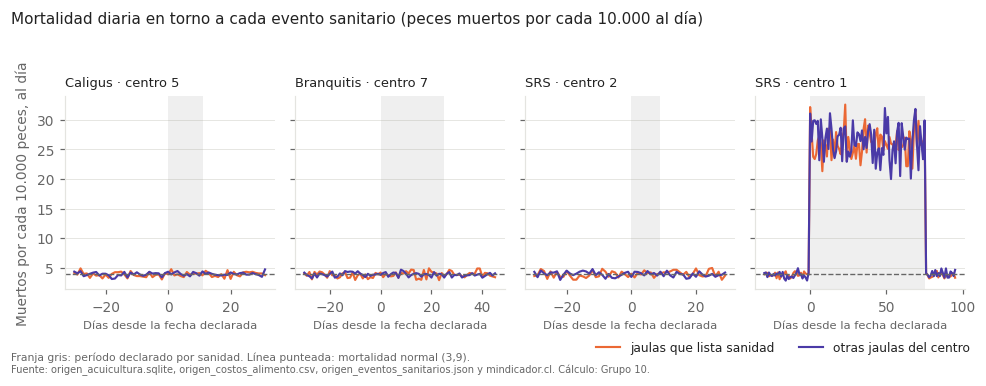

In [15]:
# Gráfico 3: mortalidad diaria en torno a cada evento (fija N y el alcance del evento)
basal_referencia = 10000 * (en_torno.loc[en_torno["dia_relativo"] < -7, "muertos"].sum()
                            / en_torno.loc[en_torno["dia_relativo"] < -7, "poblacion"].sum())
color_grupo = {"jaulas que lista sanidad": COLOR["evento"], "otras jaulas del centro": COLOR_ESPECIE[2]}
ids = list(en_torno["evento_id"].unique())

fig, ejes = plt.subplots(1, len(ids), figsize=(9, 3.4), sharey=True, squeeze=False)
for ax, evento_id in zip(ejes[0], ids):
    e = en_torno[en_torno["evento_id"] == evento_id]
    ax.axvspan(0, e["duracion_dias"].iloc[0], color="#8a8a86", alpha=0.13, linewidth=0)
    for grupo, color in color_grupo.items():
        s = e[e["grupo"] == grupo]
        ax.plot(s["dia_relativo"], s["por_10_mil"], color=color, linewidth=1.4, label=grupo)
    ax.axhline(basal_referencia, color=TENUE, linewidth=0.9, linestyle="--")
    ax.set_title(f"{e['tipo'].iloc[0]} · centro {e['centro_id'].iloc[0]}", fontsize=8.5, loc="left")
    ax.set_xlabel("Días desde la fecha declarada", fontsize=7.5)
    ax.grid(axis="x", visible=False)
ejes[0][0].set_ylabel("Muertos por cada 10.000 peces, al día")
fig.legend(*ejes[0][0].get_legend_handles_labels(), loc="lower right", bbox_to_anchor=(0.99, 0.035), ncol=2)
fig.text(0.01, 0.05, f"Franja gris: período declarado por sanidad. Línea punteada: mortalidad normal ({num(basal_referencia, 1)}).",
         fontsize=7, color=TENUE)
cerrar_grafico(fig, "3_mortalidad_y_eventos.png",
               "Mortalidad diaria en torno a cada evento sanitario (peces muertos por cada 10.000 al día)", 0.05)

**Se declara (decisión 5):** en el único evento con un aumento visible (SRS del centro 1) la mortalidad se separa de la basal **el mismo día** que sanidad declara como inicio y vuelve a lo normal al terminar el período declarado. En los días previos está en la basal. Por eso **N = 0**: la ventana va de la fecha de inicio a la fecha de término del JSON, con la misma regla para todos los eventos. Como alternativa se cuantifica N = 7.

**Decisión 6:** los eventos sin jaulas identificadas se atribuyen al centro completo. En estos datos los cuatro eventos sin jaulas son de centros que no existen en la base, así que quedaron fuera en la limpieza y la alternativa (excluirlos) da lo mismo.

**Decisión 9 (bitácora, por acordar):** en el SRS del centro 1 las jaulas que sanidad **no** lista suben igual y en las mismas fechas que las listadas. El evento alcanza a todas las jaulas del centro.

In [16]:
def ventanas_de_eventos(dec):
    """Una fila por evento y jaula alcanzada, con las fechas de su ventana."""
    filas = []
    for ev in eventos_jaulas.itertuples():
        listadas = list(ev.jaulas_afectadas)
        del_centro = jaulas.loc[jaulas["centro_id"] == ev.centro_id, "jaula_id"].tolist()
        if not listadas and dec["sin_jaulas"] == "excluir":
            continue
        alcanzadas = del_centro if (dec["alcance"] == "centro" or not listadas) else listadas
        inicio = pd.to_datetime(ev.fecha_inicio, format="%d/%m/%Y")
        for jaula in alcanzadas:
            filas.append({"evento_id": ev.evento_id, "tipo_evento": ev.tipo, "jaula_id": jaula,
                          "jaula_listada": jaula in listadas,
                          "ventana_desde": inicio - pd.Timedelta(days=dec["dias_previos"]),
                          "ventana_hasta": pd.to_datetime(ev.fecha_fin, format="%d/%m/%Y")})
    return pd.DataFrame(filas)

def cruzar_con_eventos(hechos, ventanas):
    """Marca cada jaula-día que cae dentro de la ventana de un evento."""
    cruce = hechos[["jaula_id", "fecha_dt"]].merge(ventanas, on="jaula_id")
    cruce = cruce[(cruce["fecha_dt"] >= cruce["ventana_desde"]) & (cruce["fecha_dt"] <= cruce["ventana_hasta"])]
    cruce = cruce.drop_duplicates(["jaula_id", "fecha_dt"])   # una jaula-día pertenece a un solo evento
    f = hechos.merge(cruce[["jaula_id", "fecha_dt", "evento_id", "tipo_evento", "jaula_listada"]],
                     on=["jaula_id", "fecha_dt"], how="left")
    f["en_ventana"] = f["evento_id"].notna().astype(int)   # 1 si el día está en la ventana de un evento
    return f

eventos_activos = ventanas_de_eventos(DECISIONES)
fct_cruzada = cruzar_con_eventos(fct_operacion, eventos_activos)
print("Jaulas-día en ventana de evento:", fct_cruzada["en_ventana"].sum(), "de", len(fct_cruzada))
eventos_activos.groupby(["evento_id", "tipo_evento", "ventana_desde", "ventana_hasta"], as_index=False).agg(
    jaulas_alcanzadas=("jaula_id", "count"), jaulas_listadas_por_sanidad=("jaula_listada", "sum"))

Jaulas-día en ventana de evento: 738 de 13771


,evento_id,tipo_evento,ventana_desde,ventana_hasta,jaulas_alcanzadas,jaulas_listadas_por_sanidad
0,EV-8001,SRS,2025-08-01,2025-10-15,6,4
1,EV-8002,Caligus,2025-09-17,2025-09-28,6,2
2,EV-8003,Branquitis,2025-09-03,2025-09-28,6,2
3,EV-8004,SRS,2025-04-19,2025-04-28,6,2


## Capa 4 · Consumo: la métrica (R y sus tres partes), brecha, pesos y alternativas

Las fórmulas F5 a F15 se van a mover a `metrica.py` (capa semántica, componente C) para que la métrica quede definida una sola vez y el informe y el prototipo lean lo que este notebook escribe con ella.

**6. Mortalidad basal (decisión 4, F5)**

**F5.** `b = Σ mortalidad_n ÷ Σ pob0`, sumando sobre las jaulas-día de referencia: las que están fuera de la ventana de todo evento.

**Regla principal: una tasa global.** El plan dice que vale si la mortalidad normal no cambia mucho entre etapas y que se verifica con los datos; la tabla de abajo lo verifica. La alternativa (basal por etapa del ciclo, con las mismas jaulas-día) se cuantifica en la sección 11.

In [17]:
def tasa_basal(cruzada, dec):
    """F5: agrega la columna tasa_basal a cada jaula-día, al nivel que indica la decisión 4."""
    referencia = cruzada[cruzada["en_ventana"] == 0]
    tasa_global = referencia["mortalidad_n"].sum() / referencia["pob0"].sum()
    if dec["basal"] == "global":
        return cruzada.assign(tasa_basal=tasa_global)
    sumas = referencia.groupby("etapa_peso")[["mortalidad_n", "pob0"]].sum()
    por_etapa = (sumas["mortalidad_n"] / sumas["pob0"]).rename("tasa_basal").reset_index()
    f = cruzada.merge(por_etapa, on="etapa_peso", how="left")
    f["tasa_basal"] = f["tasa_basal"].fillna(tasa_global)
    return f

referencia = fct_cruzada[fct_cruzada["en_ventana"] == 0]
BASAL_GLOBAL = referencia["mortalidad_n"].sum() / referencia["pob0"].sum()
print(f"Mortalidad basal global: {10000 * BASAL_GLOBAL:.2f} muertos por cada 10.000 peces al día "
      f"({len(referencia)} jaulas-día de referencia)")

for nivel in ["etapa_peso", "centro_id"]:
    sumas = referencia.groupby(nivel)[["mortalidad_n", "pob0"]].sum()
    print(f"\n--- Basal por {nivel} (por cada 10.000 peces al día) ---")
    print((10000 * sumas["mortalidad_n"] / sumas["pob0"]).round(2).to_string())

Mortalidad basal global: 3.92 muertos por cada 10.000 peces al día (13033 jaulas-día de referencia)

--- Basal por etapa_peso (por cada 10.000 peces al día) ---
etapa_peso
1. Engorda 100    3.94
2. Engorda 200    3.91
3. Pigmentado     3.93

--- Basal por centro_id (por cada 10.000 peces al día) ---
centro_id
1    3.92
2    3.93
3    3.95
4    3.88
5    3.93
6    3.91
7    3.93


**7. Muertes basales y de evento, y alimento perdido (decisión 7, F6 a F8)**

- **F6.** Muertes basales del día: toda la mortalidad si el día no está en una ventana; el mínimo entre la mortalidad y `b × pob0` si está.
- **F7.** Muertes de evento: `m_evento = mortalidad_n − m_basal`. Es el exceso sobre la basal dentro de la ventana, lo único que se atribuye al evento.
- **F8.** Alimento perdido por tipo: `P_basal = Σ m_basal × A(d)` y `P_evento = Σ m_evento × A(d)`.

**Decisión 7:** se usa la mortalidad diaria por jaula (`mortalidad_n`), que tiene el grano del modelo. La alternativa (la mortalidad que declara sanidad, repartida entre los días de la ventana en proporción a la mortalidad diaria) se cuantifica en la sección 11.

In [18]:
def separar_muertes(cruzada, dec):
    f = tasa_basal(cruzada, dec)
    esperadas = f["tasa_basal"] * f["pob0"]

    if dec["mortalidad"] == "diaria":
        # F6: en ventana, las muertes basales son a lo más lo que predice la basal
        f["m_basal"] = f["mortalidad_n"].where(f["en_ventana"] == 0, pd.concat([f["mortalidad_n"], esperadas], axis=1).min(axis=1))
    else:
        # Alternativa: las muertes del evento son las que declara sanidad, repartidas entre los
        # días de la ventana en proporción a la mortalidad diaria (con tope en ella)
        declarada = f["evento_id"].map(eventos_jaulas.set_index("evento_id")["mortalidad_asociada"].astype(float))
        en_ventana = f.groupby("evento_id")["mortalidad_n"].transform("sum")
        parte = (declarada / en_ventana).fillna(0).clip(upper=1)
        f["m_basal"] = f["mortalidad_n"] * (1 - parte)

    f["m_evento"] = f["mortalidad_n"] - f["m_basal"]   # F7

    # F8 (y su versión en pesos, F14): alimento que ya se habían comido los peces que murieron
    for unidad in ["kg", "clp"]:
        f[f"perdido_basal_{unidad}"] = f["m_basal"] * f[f"acumulado_por_pez_{unidad}"]
        f[f"perdido_evento_{unidad}"] = f["m_evento"] * f[f"acumulado_por_pez_{unidad}"]
    return f

fct_final = separar_muertes(fct_cruzada, DECISIONES)

print("--- Muestra: días en ventana de evento ---")
fct_final[fct_final["en_ventana"] == 1][["fecha_dt", "jaula_id", "evento_id", "mortalidad_n", "m_basal", "m_evento",
                                         "acumulado_por_pez_kg", "perdido_evento_kg"]].head(10)

--- Muestra: días en ventana de evento ---


,fecha_dt,jaula_id,evento_id,mortalidad_n,m_basal,m_evento,acumulado_por_pez_kg,perdido_evento_kg
212,2025-08-01,1,EV-8001,152,18.177325,133.822675,4.322303,578.422212
213,2025-08-02,1,EV-8001,153,18.117713,134.882287,4.335681,584.806563
214,2025-08-03,1,EV-8001,134,18.057709,115.942291,4.348864,504.217256
215,2025-08-04,1,EV-8001,89,18.005157,70.994843,4.361781,309.663930
216,2025-08-05,1,EV-8001,93,17.970252,75.029748,4.376228,328.347291
217,2025-08-06,1,EV-8001,139,17.933779,121.066221,4.390115,531.494580
218,2025-08-07,1,EV-8001,105,17.879266,87.120734,4.406588,383.905169
219,2025-08-08,1,EV-8001,146,17.838086,128.161914,4.423693,566.948930
220,2025-08-09,1,EV-8001,88,17.780828,70.219172,4.439154,311.713749
221,2025-08-10,1,EV-8001,104,17.746315,86.253685,4.453210,384.105741


**Conciliación con la mortalidad que declara sanidad**

El correo advierte que la mortalidad declarada por evento no va a calzar con la suma de la mortalidad diaria, porque son dos registros de áreas distintas. La tabla compara por evento lo que declara sanidad con la mortalidad diaria del período (en las jaulas que lista sanidad y en el centro completo), y muestra las muertes atribuidas al evento y el alimento que se perdió con ellas.

In [19]:
def conciliar_eventos(final):
    filas = []
    for ev in eventos_jaulas.itertuples():
        inicio = pd.to_datetime(ev.fecha_inicio, format="%d/%m/%Y")
        fin = pd.to_datetime(ev.fecha_fin, format="%d/%m/%Y")
        periodo = final[(final["fecha_dt"] >= inicio) & (final["fecha_dt"] <= fin) & (final["centro_id"] == ev.centro_id)]
        del_evento = final[final["evento_id"] == ev.evento_id]
        muertes = del_evento["m_evento"].sum()
        filas.append({
            "evento_id": ev.evento_id, "tipo": ev.tipo, "centro_id": ev.centro_id,
            "declarada_sanidad": int(ev.mortalidad_asociada),
            "diaria_jaulas_listadas": periodo[periodo["jaula_id"].isin(ev.jaulas_afectadas)]["mortalidad_n"].sum(),
            "diaria_centro_completo": periodo["mortalidad_n"].sum(),
            "muertes_de_evento": muertes,
            "alimento_perdido_kg": del_evento["perdido_evento_kg"].sum(),
            "alimento_perdido_mm_clp": del_evento["perdido_evento_clp"].sum() / 1e6,
            "alimento_por_pez_muerto_kg": del_evento["perdido_evento_kg"].sum() / muertes if muertes else float("nan"),
            "dias_a_cosecha_promedio": (del_evento["fecha_cosecha"] - del_evento["fecha_dt"]).dt.days.mean(),
        })
    return pd.DataFrame(filas)

conciliacion = conciliar_eventos(fct_final)
conciliacion.round(1)

,evento_id,tipo,centro_id,declarada_sanidad,diaria_jaulas_listadas,diaria_centro_completo,muertes_de_evento,alimento_perdido_kg,alimento_perdido_mm_clp,alimento_por_pez_muerto_kg,dias_a_cosecha_promedio
0,EV-8002,Caligus,5,5226,496,1791,149.1,562.8,0.6,3.8,63.3
1,EV-8003,Branquitis,7,2790,1528,4075,308.5,997.8,1.1,3.2,80.5
2,EV-8004,SRS,2,8420,562,1639,156.0,354.4,0.4,2.3,205.6
3,EV-8001,SRS,1,62478,41078,61714,52488.1,256280.3,282.6,4.9,83.4


**8. R y sus tres partes (decisión 1, F9 a F12)**

Por lote:

- **F9.** Alimento transformado en biomasa cosechada: `A_cosecha = alimento total − P_basal − P_evento`.
- **F10.** `R = alimento total ÷ kg cosechados = R_cosecha + R_evento + R_basal`.
- **F11.** % del alimento de cada parte; las tres suman 100 %.
- **F12.** Para un centro, una especie o un centro × especie se suman numeradores y denominadores de sus lotes y recién entonces se divide. No se promedian razones.

`R_bruto_gerencia` es la cifra que usa hoy la gerencia (alimento ÷ biomasa final) y se muestra sólo como referencia.

In [20]:
SUMAS = ["alimento_kg", "costo_clp", "denominador_kg", "kg_cosechados", "biomasa_final_kg", "m_basal", "m_evento",
         "cosecha_kg", "evento_kg", "basal_kg", "cosecha_clp", "evento_clp", "basal_clp"]

def tabla_por_lote(final, dec):
    lote = final.groupby(["centro_id", "especie", "lote_id"], as_index=False).agg(
        alimento_kg=("alimento_kg", "sum"), costo_clp=("costo_alimento_clp", "sum"),
        biomasa_inicial_kg=("biomasa_kg", "first"), biomasa_final_kg=("biomasa_kg", "last"),
        m_basal=("m_basal", "sum"), m_evento=("m_evento", "sum"),
        basal_kg=("perdido_basal_kg", "sum"), evento_kg=("perdido_evento_kg", "sum"),
        basal_clp=("perdido_basal_clp", "sum"), evento_clp=("perdido_evento_clp", "sum"),
    )
    lote = lote.merge(cosechas_validas[["lote_id", "kilos_vivos"]].rename(columns={"kilos_vivos": "kg_cosechados"}), on="lote_id")
    # F9: lo que no se perdió en peces muertos es lo que comieron los peces cosechados
    lote["cosecha_kg"] = lote["alimento_kg"] - lote["basal_kg"] - lote["evento_kg"]
    lote["cosecha_clp"] = lote["costo_clp"] - lote["basal_clp"] - lote["evento_clp"]
    # Decisión 1: denominador
    if dec["denominador"] == "cosechado":
        lote["denominador_kg"] = lote["kg_cosechados"]
    else:   # biomasa ganada: cosechada − biomasa del lote en su primer registro
        lote["denominador_kg"] = lote["kg_cosechados"] - lote["biomasa_inicial_kg"]
    return lote

def indicadores(sumas):
    """F10, F11 y F14 sobre una tabla que ya trae sumados numeradores y denominadores."""
    g = sumas.copy()
    g["R"] = g["alimento_kg"] / g["denominador_kg"]
    for parte in ["cosecha", "evento", "basal"]:
        g[f"R_{parte}"] = g[f"{parte}_kg"] / g["denominador_kg"]
        g[f"pct_{parte}"] = 100 * g[f"{parte}_kg"] / g["alimento_kg"]
        g[f"clp_por_kg_{parte}"] = g[f"{parte}_clp"] / g["denominador_kg"]
    g["clp_por_kg"] = g["costo_clp"] / g["denominador_kg"]
    g["usd_por_kg"] = g["clp_por_kg"] / DOLAR_PERIODO
    g["R_bruto_gerencia"] = g["alimento_kg"] / g["biomasa_final_kg"]
    return g

def agregar(por_lote, por):
    """F12: suma los lotes y recién entonces divide."""
    sumas = por_lote.groupby(por)[SUMAS].sum()
    sumas.insert(0, "lotes", por_lote.groupby(por).size())
    return indicadores(sumas)

por_lote = tabla_por_lote(fct_final, DECISIONES)
por_centro = agregar(por_lote, ["centro_id"])
por_especie = agregar(por_lote, ["especie"])
por_centro_especie = agregar(por_lote, ["centro_id", "especie"])

CENTRO_CARO = por_centro["R"].idxmax()
nombre_centro = centros.set_index("centro_id")["nombre"]
print(f"Centro con más costo (mayor R): {CENTRO_CARO} ({nombre_centro[CENTRO_CARO]})")

columnas_R = ["lotes", "alimento_kg", "kg_cosechados", "R", "R_cosecha", "R_evento", "R_basal",
              "pct_cosecha", "pct_evento", "pct_basal", "R_bruto_gerencia"]
por_centro[columnas_R].round(3)

Centro con más costo (mayor R): 1 (Centro Reloncaví)


,lotes,alimento_kg,kg_cosechados,R,R_cosecha,R_evento,R_basal,pct_cosecha,pct_evento,pct_basal,R_bruto_gerencia
centro_id,,,,,,,,,,,
1,6,2238604.0,1282975,1.745,1.431,0.200,0.114,82.034,11.448,6.518,1.744
2,6,2133050.0,1625848,1.312,1.227,0.000,0.085,93.521,0.017,6.463,1.311
3,6,2153872.0,1710079,1.260,1.175,0.000,0.085,93.256,0.000,6.744,1.259
4,6,1727467.0,1387589,1.245,1.161,0.000,0.084,93.292,0.000,6.708,1.244
5,6,1832892.0,1498932,1.223,1.141,0.000,0.082,93.289,0.031,6.680,1.222
6,6,1852733.0,1554145,1.192,1.113,0.000,0.079,93.398,0.000,6.602,1.192
7,6,1794740.0,1506134,1.192,1.110,0.001,0.081,93.154,0.056,6.790,1.191


In [21]:
print("--- Por especie ---")
display(por_especie[columnas_R].round(3))
print("--- Por centro y especie: R_cosecha (eficiencia de los peces cosechados) ---")
por_centro_especie["R_cosecha"].unstack("especie").round(3)

--- Por especie ---


,lotes,alimento_kg,kg_cosechados,R,R_cosecha,R_evento,R_basal,pct_cosecha,pct_evento,pct_basal,R_bruto_gerencia
especie,,,,,,,,,,,
Salmón Coho,10,3351496.0,2514224,1.333,1.204,0.042,0.087,90.305,3.169,6.526,1.332
Salmón del Atlántico,26,8487175.0,6543966,1.297,1.192,0.018,0.087,91.943,1.367,6.689,1.296
Trucha,6,1894687.0,1507512,1.257,1.150,0.024,0.083,91.502,1.897,6.601,1.256


--- Por centro y especie: R_cosecha (eficiencia de los peces cosechados) ---


especie,Salmón Coho,Salmón del Atlántico,Trucha
centro_id,,,
1,1.412,1.429,1.504
2,1.258,1.242,1.189
3,1.124,1.181,NaN
4,NaN,1.161,NaN
5,1.118,1.164,NaN
6,1.080,1.144,1.049
7,1.184,1.087,1.057


**9. Brecha del centro con más costo (F13)**

**F13.** `ΔR = R(centro más caro) − R(resto) = Σ ΔR_x`; el aporte de cada parte es `ΔR_x ÷ ΔR`. El resto es la suma de los demás centros (F12). Esta tabla es la respuesta a la pregunta: si pesa más la parte *evento*, la causa es sanitaria; si pesa más *cosecha*, es un FCR peor; si pesan ambas, es una combinación.

In [22]:
def brecha_centro_caro(por_centro, caro):
    resto = indicadores(por_centro.drop(index=caro)[SUMAS].sum().to_frame().T).iloc[0]
    centro = por_centro.loc[caro]
    filas = []
    for parte, sufijo in [("cosecha", "_cosecha"), ("evento", "_evento"), ("basal", "_basal"), ("total", "")]:
        filas.append({
            "parte": parte,
            "R_centro_caro": centro[f"R{sufijo}"], "R_resto": resto[f"R{sufijo}"],
            "brecha_R": centro[f"R{sufijo}"] - resto[f"R{sufijo}"],
            "brecha_clp_por_kg": centro[f"clp_por_kg{sufijo}"] - resto[f"clp_por_kg{sufijo}"],
        })
    b = pd.DataFrame(filas).set_index("parte")
    b["aporte_pct"] = 100 * b["brecha_R"] / b.loc["total", "brecha_R"]
    # F14: lo que el centro gastó de más en alimento por no rendir como el resto
    b["sobrecosto_mm_clp"] = b["brecha_clp_por_kg"] * centro["denominador_kg"] / 1e6
    return b

brecha = brecha_centro_caro(por_centro, CENTRO_CARO)
brecha.round(3)

,R_centro_caro,R_resto,brecha_R,brecha_clp_por_kg,aporte_pct,sobrecosto_mm_clp
parte,,,,,,
cosecha,1.431,1.156,0.276,314.235,54.437,403.155
evento,0.200,0.000,0.200,220.071,39.393,282.345
basal,0.114,0.082,0.031,34.152,6.170,43.817
total,1.745,1.238,0.507,568.458,100.000,729.317


**10. Conversión a pesos (F14)**

**F14.** Se repiten F2 a F10 reemplazando `alimento_kg` por `alimento_kg × precio del mes`. Pesos por kg cosechado = costo total ÷ kg cosechados. Como el precio es el mismo para todas las jaulas, el orden de los centros en pesos es el mismo que en R. El dólar entra sólo para expresar la cifra en USD (promedio del período).

In [23]:
en_pesos = por_centro[["clp_por_kg", "clp_por_kg_cosecha", "clp_por_kg_evento", "clp_por_kg_basal", "usd_por_kg"]].copy()
en_pesos.insert(0, "nombre", nombre_centro)
en_pesos["perdido_evento_mm_clp"] = por_centro["evento_clp"] / 1e6
en_pesos["perdido_basal_mm_clp"] = por_centro["basal_clp"] / 1e6

sobrecosto = brecha["sobrecosto_mm_clp"]
print(f"El centro {CENTRO_CARO} gastó CLP {num(sobrecosto['total'], 0)} millones más en alimento de lo que habría gastado "
      f"rindiendo como el resto ("
      + ("USD no disponible: sin dólar de la API ni copia guardada" if pd.isna(DOLAR_PERIODO)
         else f"USD {num(sobrecosto['total'] * 1e6 / DOLAR_PERIODO / 1e3, 0)} mil") + "):")
for parte in ["cosecha", "evento", "basal"]:
    print(f"  {NOMBRE[parte]:<32} CLP {num(sobrecosto[parte], 0):>4} millones")
en_pesos.round(2)

El centro 1 gastó CLP 729 millones más en alimento de lo que habría gastado rindiendo como el resto (USD 767 mil):
  Peces cosechados (eficiencia)    CLP  403 millones
  Muertes por evento sanitario     CLP  282 millones
  Mortalidad normal (basal)        CLP   44 millones


,nombre,clp_por_kg,clp_por_kg_cosecha,clp_por_kg_evento,clp_por_kg_basal,usd_por_kg,perdido_evento_mm_clp,perdido_basal_mm_clp
centro_id,,,,,,,,
1,Centro Reloncaví,1959.30,1614.93,220.30,124.08,2.06,282.63,159.19
2,Centro Calbuco,1470.30,1377.71,0.23,92.36,1.55,0.37,150.16
3,Centro Quellón,1417.58,1324.81,0.00,92.77,1.49,0.00,158.65
4,Centro Melinka,1400.09,1308.96,0.00,91.13,1.47,0.00,126.45
5,Centro Cisnes,1373.06,1283.61,0.41,89.04,1.44,0.62,133.47
6,Centro Puyuhuapi,1336.62,1250.91,0.00,85.71,1.41,0.00,133.20
7,Centro Skyring,1339.87,1250.94,0.73,88.20,1.41,1.10,132.84


**11. Sensibilidad a cada decisión (F15)**

**F15.** `cambio = (valor con la alternativa − valor final) ÷ valor final`, en R, en los % y en la brecha, para cada decisión de la sección 3 del plan. Se cambia **una decisión a la vez**; el resto queda en la principal.

In [24]:
def correr(dec):
    """Corre el análisis completo con un juego de decisiones y devuelve las cifras que se comparan."""
    hechos = construir_hechos(dec)
    final = separar_muertes(cruzar_con_eventos(hechos, ventanas_de_eventos(dec)), dec)
    centro = agregar(tabla_por_lote(final, dec), ["centro_id"])
    caro = centro["R"].idxmax()
    b = brecha_centro_caro(centro, caro)
    referencia = final[final["en_ventana"] == 0]
    return {
        "centro_mas_caro": caro,
        "R_centro": centro.loc[caro, "R"], "R_resto": b.loc["total", "R_resto"], "brecha_R": b.loc["total", "brecha_R"],
        "pct_cosecha": centro.loc[caro, "pct_cosecha"], "pct_evento": centro.loc[caro, "pct_evento"],
        "pct_basal": centro.loc[caro, "pct_basal"],
        "aporte_cosecha": b.loc["cosecha", "aporte_pct"], "aporte_evento": b.loc["evento", "aporte_pct"],
        "aporte_basal": b.loc["basal", "aporte_pct"],
        "clp_por_kg_centro": centro.loc[caro, "clp_por_kg"],
        "perdido_evento_ton": centro["evento_kg"].sum() / 1000,
        "basal_por_10000": 10000 * referencia["mortalidad_n"].sum() / referencia["pob0"].sum(),
    }

ALTERNATIVAS = {
    "Principal": {},
    "1 · denominador: biomasa ganada": {"denominador": "ganada"},
    "2 · precio según el peso del pez": {"precio": "por_peso"},
    "3 · perdido = peso promedio x FCR": {"perdido": "peso_fcr"},
    "4 · basal por etapa del ciclo": {"basal": "etapa"},
    "5 · ventana desde 7 días antes": {"dias_previos": 7},
    "6 · excluir eventos sin jaulas": {"sin_jaulas": "excluir"},
    "7 · mortalidad declarada por sanidad": {"mortalidad": "sanidad"},
    "8 · población ya sin los muertos del día": {"lectura": "despues"},
    "9 · sólo las jaulas que lista sanidad": {"alcance": "declaradas"},
}

sensibilidad = pd.DataFrame({nombre: correr({**DECISIONES, **cambio}) for nombre, cambio in ALTERNATIVAS.items()}).T.astype(float)
base = sensibilidad.loc["Principal"]
for columna in ["R_centro", "brecha_R", "clp_por_kg_centro", "perdido_evento_ton"]:
    sensibilidad[f"cambio_%_{columna}"] = 100 * (sensibilidad[columna] / base[columna] - 1)   # F15

sensibilidad[["centro_mas_caro", "R_centro", "R_resto", "brecha_R", "aporte_cosecha", "aporte_evento", "aporte_basal",
              "clp_por_kg_centro", "cambio_%_R_centro", "cambio_%_brecha_R", "cambio_%_clp_por_kg_centro",
              "cambio_%_perdido_evento_ton"]].round(2)

,centro_mas_caro,R_centro,R_resto,brecha_R,aporte_cosecha,aporte_evento,aporte_basal,clp_por_kg_centro,cambio_%_R_centro,cambio_%_brecha_R,cambio_%_clp_por_kg_centro,cambio_%_perdido_evento_ton
Principal,1.0,1.74,1.24,0.51,54.44,39.39,6.17,1959.30,0.00,0.00,0.00,0.00
1 · denominador: biomasa ganada,1.0,1.95,1.38,0.57,54.85,38.97,6.18,2189.83,11.77,12.97,11.77,0.00
2 · precio según el peso del pez,1.0,1.74,1.24,0.51,54.44,39.39,6.17,1917.83,0.00,0.00,-2.12,0.00
3 · perdido = peso promedio x FCR,1.0,1.74,1.24,0.51,48.97,43.97,7.06,1959.30,0.00,0.00,0.00,11.66
4 · basal por etapa del ciclo,1.0,1.74,1.24,0.51,54.44,39.40,6.16,1959.30,0.00,0.00,0.00,0.03
5 · ventana desde 7 días antes,1.0,1.74,1.24,0.51,54.44,39.41,6.15,1959.30,0.00,0.00,0.00,0.34
6 · excluir eventos sin jaulas,1.0,1.74,1.24,0.51,54.44,39.39,6.17,1959.30,0.00,0.00,0.00,0.00
7 · mortalidad declarada por sanidad,1.0,1.74,1.24,0.51,54.44,45.95,-0.39,1959.30,0.00,0.00,0.00,24.26
8 · población ya sin los muertos del día,1.0,1.74,1.24,0.51,54.47,39.35,6.18,1959.30,0.00,0.00,0.00,-0.10
9 · sólo las jaulas que lista sanidad,1.0,1.74,1.24,0.51,54.44,25.96,19.60,1959.30,0.00,0.00,0.00,-34.47


In [25]:
# Las mismas cifras por centro y la brecha bajo cada definición alternativa, para que el prototipo
# las muestre como medidas seleccionables sin recalcular (C4). Usa las mismas funciones de arriba.
# Cada definición se corre una sola vez aquí: la capa del prototipo (al final) reutiliza estas corridas.
def corrida_con(dec):
    """Tabla final jaula-día e indicadores por centro bajo un juego de decisiones."""
    final = separar_muertes(cruzar_con_eventos(construir_hechos(dec), ventanas_de_eventos(dec)), dec)
    return final, agregar(tabla_por_lote(final, dec), ["centro_id"])

corridas_alt = {}   # definición -> (tabla final jaula-día, indicadores por centro)
tablas_alt, brechas_alt = [], []
for nombre, cambio in ALTERNATIVAS.items():
    final_alt, pc = corrida_con({**DECISIONES, **cambio})
    corridas_alt[nombre] = (final_alt, pc)
    tablas_alt.append(pc.reset_index().assign(definicion=nombre))
    brechas_alt.append(brecha_centro_caro(pc, pc["R"].idxmax()).reset_index().assign(definicion=nombre))
alternativas_por_centro = pd.concat(tablas_alt, ignore_index=True)
brecha_alternativas = pd.concat(brechas_alt, ignore_index=True)
brecha_alternativas.pivot(index="definicion", columns="parte", values="aporte_pct").round(1)

parte,basal,cosecha,evento,total
definicion,,,,
1 · denominador: biomasa ganada,6.2,54.9,39.0,100.0
2 · precio según el peso del pez,6.2,54.4,39.4,100.0
3 · perdido = peso promedio x FCR,7.1,49.0,44.0,100.0
4 · basal por etapa del ciclo,6.2,54.4,39.4,100.0
5 · ventana desde 7 días antes,6.1,54.4,39.4,100.0
6 · excluir eventos sin jaulas,6.2,54.4,39.4,100.0
7 · mortalidad declarada por sanidad,-0.4,54.4,46.0,100.0
8 · población ya sin los muertos del día,6.2,54.5,39.4,100.0
9 · sólo las jaulas que lista sanidad,19.6,54.4,26.0,100.0


**12. Gráficos (componente E)**

Cada gráfico lleva la unidad en el título y la fuente al pie, y se prepara en `results/.en_preparacion/figuras/` y se publica en `figuras/` al final, solo si las pruebas que bloquean pasan. El gráfico 3 (mortalidad en torno a los eventos) está en la sección 5, donde fija N.

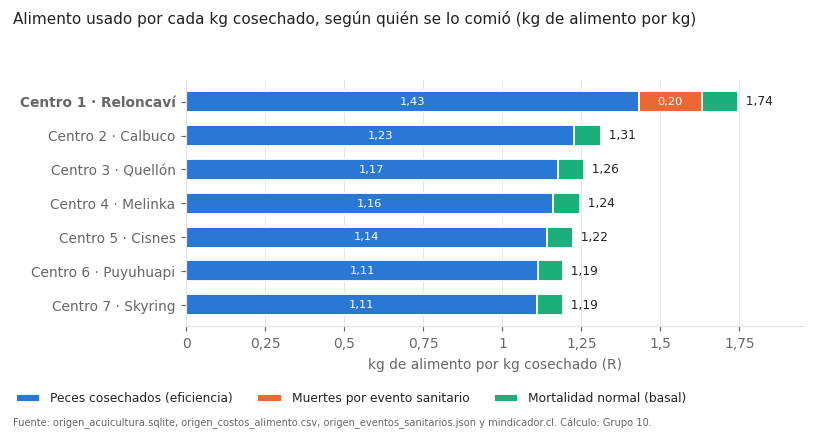

In [26]:
def barras_apiladas(ax, etiquetas, tabla, prefijo, partes, decimales, sufijo=""):
    """Barras horizontales apiladas por parte, con el valor de cada tramo y el total al final."""
    izquierda = pd.Series(0.0, index=tabla.index)
    total = tabla[[f"{prefijo}{p}" for p in partes]].sum(axis=1)
    for p in partes:
        valores = tabla[f"{prefijo}{p}"]
        ax.barh(etiquetas, valores, left=izquierda, color=COLOR[p], edgecolor="white", linewidth=1.2, height=0.62,
                label=NOMBRE[p])
        for y, (x0, ancho) in enumerate(zip(izquierda, valores)):
            if ancho >= 0.075 * total.max():
                ax.text(x0 + ancho / 2, y, num(ancho, decimales), ha="center", va="center", fontsize=7.5, color="white")
        izquierda = izquierda + valores
    for y, valor in enumerate(total):
        ax.text(valor, y, f"  {num(valor, decimales)}{sufijo}", va="center", fontsize=8, color=TINTA)
    ax.set_xlim(0, total.max() * 1.12)
    ax.grid(axis="y", visible=False)
    eje_con_coma(ax)

# Gráfico 1: R por centro en sus tres partes
t = por_centro.sort_values("R")
etiquetas = [f"Centro {i} · {nombre_centro[i].replace('Centro ', '')}" for i in t.index]
fig, ax = plt.subplots(figsize=(7.4, 3.9))
barras_apiladas(ax, etiquetas, t, "R_", PARTES, 2)
ax.get_yticklabels()[list(t.index).index(CENTRO_CARO)].set_fontweight("bold")
ax.set_xlabel("kg de alimento por kg cosechado (R)")
fig.legend(*ax.get_legend_handles_labels(), loc="lower left", bbox_to_anchor=(0.0, 0.04), ncol=3)
cerrar_grafico(fig, "1_R_por_centro.png",
               "Alimento usado por cada kg cosechado, según quién se lo comió (kg de alimento por kg)", 0.07)

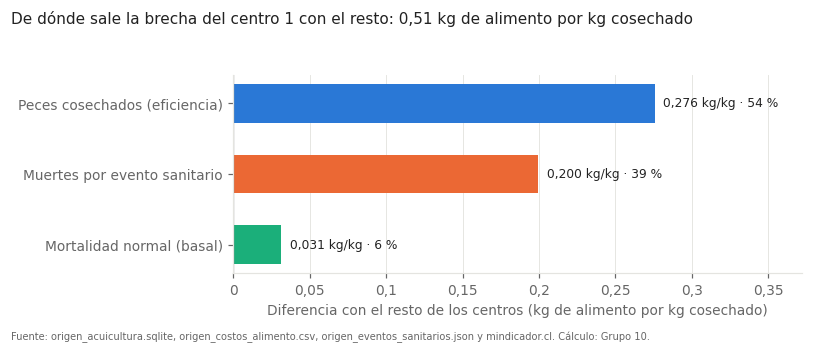

In [27]:
# Gráfico 2: de dónde sale la brecha del centro más caro con el resto
b = brecha.drop(index="total")
fig, ax = plt.subplots(figsize=(7.4, 3.1))
ax.barh([NOMBRE[p] for p in b.index], b["brecha_R"], color=[COLOR[p] for p in b.index], height=0.55)
ax.axvline(0, color=TENUE, linewidth=0.8)
tope = b["brecha_R"].abs().max()
for y, (valor, pct) in enumerate(zip(b["brecha_R"], b["aporte_pct"])):
    ax.text(valor + 0.02 * tope, y, f"{num(valor, 3)} kg/kg · {num(pct, 0)} %", va="center", ha="left", fontsize=8)
ax.set_xlim(min(0, b["brecha_R"].min()), tope * 1.35)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Diferencia con el resto de los centros (kg de alimento por kg cosechado)")
eje_con_coma(ax)
cerrar_grafico(fig, "2_brecha_centro_caro.png",
               f"De dónde sale la brecha del centro {CENTRO_CARO} con el resto: "
               f"{num(brecha.loc['total', 'brecha_R'], 2)} kg de alimento por kg cosechado")

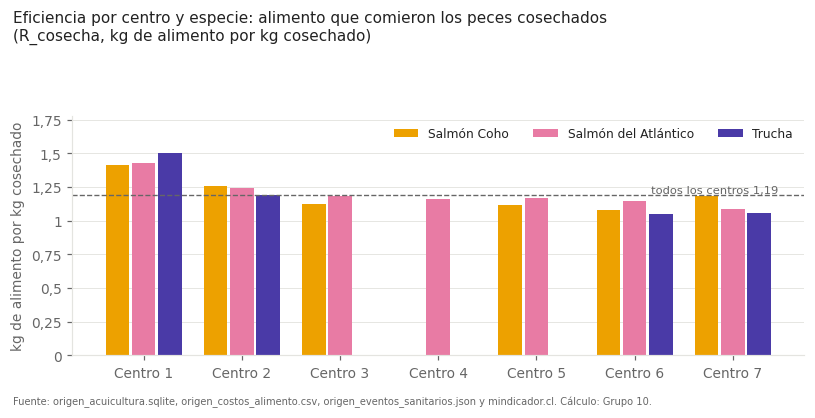

In [28]:
# Gráfico 4: eficiencia (R_cosecha) por centro y especie
t = por_centro_especie["R_cosecha"].unstack("especie")
lista_especies = list(t.columns)
ancho = 0.8 / len(lista_especies)
fig, ax = plt.subplots(figsize=(7.4, 3.7))
for k, especie in enumerate(lista_especies):
    x = [i + (k - (len(lista_especies) - 1) / 2) * ancho for i in range(len(t))]
    ax.bar(x, t[especie], width=ancho * 0.9, color=COLOR_ESPECIE[k], label=especie)
general = por_centro["cosecha_kg"].sum() / por_centro["denominador_kg"].sum()
ax.axhline(general, color=TENUE, linewidth=0.9, linestyle="--")
ax.text(len(t) - 0.5, general, f"todos los centros {num(general, 2)} ", ha="right", va="bottom", fontsize=7.5, color=TENUE)
ax.set_xticks(range(len(t)), [f"Centro {i}" for i in t.index])
ax.set_ylim(0, float(t.max().max()) * 1.18)
ax.grid(axis="x", visible=False)
ax.set_ylabel("kg de alimento por kg cosechado")
ax.legend(loc="upper right", ncol=len(lista_especies))
eje_con_coma(ax, "y")
cerrar_grafico(fig, "4_eficiencia_centro_especie.png",
               "Eficiencia por centro y especie: alimento que comieron los peces cosechados\n"
               "(R_cosecha, kg de alimento por kg cosechado)")

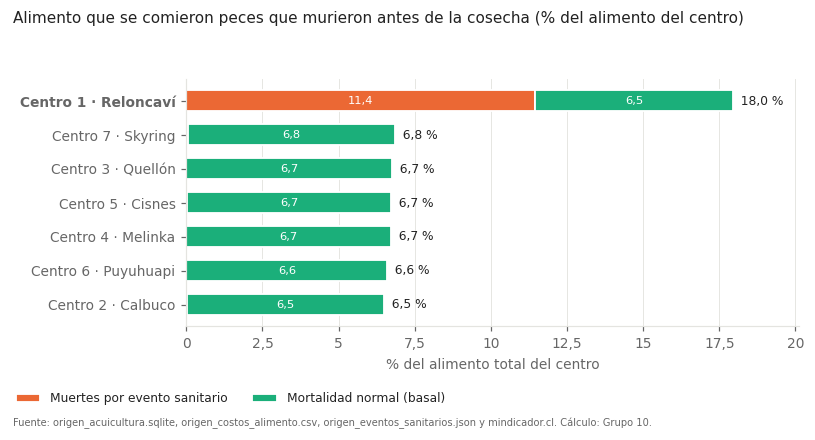

In [29]:
# Gráfico 5: % del alimento que se perdió en peces muertos, por centro
t = por_centro.assign(perdido=por_centro["pct_evento"] + por_centro["pct_basal"]).sort_values("perdido")
etiquetas = [f"Centro {i} · {nombre_centro[i].replace('Centro ', '')}" for i in t.index]
fig, ax = plt.subplots(figsize=(7.4, 3.9))
barras_apiladas(ax, etiquetas, t, "pct_", ["evento", "basal"], 1, " %")
ax.get_yticklabels()[list(t.index).index(CENTRO_CARO)].set_fontweight("bold")
ax.set_xlabel("% del alimento total del centro")
fig.legend(*ax.get_legend_handles_labels(), loc="lower left", bbox_to_anchor=(0.0, 0.04), ncol=2)
cerrar_grafico(fig, "5_alimento_perdido_por_centro.png",
               "Alimento que se comieron peces que murieron antes de la cosecha (% del alimento del centro)", 0.07)

## Calidad · Pruebas de la corrida

Corren en cada ejecución, sobre los datos reales (`calidad.py`). Cada una dice qué verifica, si **bloquea** (la corrida no publica) o **avisa** (sigue y lo registra), y su resultado. Las pruebas previas de las fuentes (F-01, F-02, F-05, F-09) y la de la API (F-13) ya corrieron más arriba.

In [30]:
periodo = PERIODO
calidad.pruebas_fuentes(registro, operacion_diaria, cosechas, lotes, productos, dim_costos, operacion_limpia, crudo,
                        eventos_jaulas, eventos_activos, tabla_cobertura, filas_csv, periodo)
calidad.pruebas_hechos(registro, fct_final, lotes, jaulas, centros, especies, cosechas, cosechas_validas, por_lote,
                       tabla_cobertura, total_op, comprobaciones, periodo)
calidad.pruebas_metrica(registro, por_lote, por_centro, por_especie, brecha, tabla_cobertura, total_op, fct_final,
                        sensibilidad, REFERENCIA_E1, SLA["completitud_min_pct"])
detener_si_bloqueo(registro, "pruebas de la tabla de hechos y de la métrica")

[  ok   ] F-03 Todas las fechas se leen en alguno de los 4 formatos -> {'operacion_diaria.fecha': 0, 'cosechas.fecha': 0, 'lotes.fecha_siembra': 0}
[  ok   ] F-04 Los números (punto de miles, coma decimal) se leen -> {'alimento_kg': 0, 'biomasa_kg': 0, 'crecimiento_kg': 0, 'mortalidad_n': 0, 'kilos_vivos': 0}
[  ok   ] F-06 Cada mes de operación tiene precio > 0 -> 12 de 12 meses con precio
[  ok   ] F-07 Todos los precios vienen en CLP -> ['CLP']
[  ok   ] F-08 Filas descartadas (títulos, TOTAL, «sin dato») dentro de lo esperado -> 3 de 36 filas descartadas
[  ok   ] F-10 Inicio ≤ fin y ambas fechas dentro del período -> 0 eventos con fechas invertidas o fuera del período
[  ok   ] F-11 Eventos de centros que no existen: excluidos y contados -> 4 de 8 excluidos y contados en la cobertura
[  ok   ] F-12 Cada evento válido alcanza al menos una jaula (decisiones 6 y 9) -> 4 de 4 eventos alcanzan jaulas
[  ok   ] H-01 Unicidad de la clave del hecho: una fila por (lote, fecha) -> 0 duplica

## Salidas · Publicación en `results/`

Todo se escribe primero en `results/.en_preparacion/`. Solo si las pruebas que bloquean pasan, reemplaza a `results/` y las figuras pasan a `figuras/`. Si algo falla, el prototipo sigue leyendo la última versión publicada y `estado_corrida.json` dice de qué fecha es.

In [31]:
def f(x):
    return None if pd.isna(x) else round(float(x), 6)

caro = int(CENTRO_CARO)
excluidos_op = int(tabla_cobertura.query("fuente == 'operacion_diaria' and tipo == 'excluido'")["registros"].sum())
total_mm = brecha.loc["total", "sobrecosto_mm_clp"]


def rango(parte, columna):
    """Cifra de referencia (definición principal) y su rango entre las 10 definiciones, con la que da cada extremo."""
    serie = brecha_alternativas[brecha_alternativas["parte"] == parte].set_index("definicion")[columna]
    return {"principal": f(serie["Principal"]), "min": f(serie.min()), "max": f(serie.max()),
            "definicion_min": serie.idxmin(), "definicion_max": serie.idxmax()}

cifras = {
    "pregunta": "En el centro con más costo, ¿la causa es la mortalidad de un evento sanitario, un FCR peor, o ambas?",
    "fecha_corrida": FECHA_CORRIDA,
    "metrica": "R = kg de alimento ÷ kg cosechados = R_cosecha + R_evento + R_basal",
    "centro_mas_caro": {"id": caro, "nombre": nombre_centro[caro]},
    "R": {"centro": f(por_centro.loc[caro, "R"]), "resto": f(brecha.loc["total", "R_resto"]),
          "brecha": f(brecha.loc["total", "brecha_R"])},
    "partes_centro": {p: f(por_centro.loc[caro, f"R_{p}"]) for p in PARTES},
    "partes_resto": {p: f(brecha.loc[p, "R_resto"]) for p in PARTES},
    "aporte_brecha_pct": {p: f(brecha.loc[p, "aporte_pct"]) for p in PARTES},
    "sobrecosto_mm_clp": {**{p: f(brecha.loc[p, "sobrecosto_mm_clp"]) for p in PARTES}, "total": f(total_mm)},
    # FCR bruto (alimento ÷ biomasa final): el indicador que la gerencia reporta al directorio, junto a R
    "fcr_bruto_centro": f(por_centro.loc[caro, "R_bruto_gerencia"]),
    "fcr_bruto_resto": f(indicadores(por_centro.drop(index=caro)[SUMAS].sum().to_frame().T).iloc[0]["R_bruto_gerencia"]),
    "clp_por_kg_cosechado_centro": f(por_centro.loc[caro, "clp_por_kg"]),
    "usd": {"sobrecosto_total_miles": f(total_mm * 1e6 / DOLAR_PERIODO / 1e3), "dolar_promedio_periodo": f(DOLAR_PERIODO),
            "dolar_origen": origen_dolar},
    "cobertura": {"registros_jaula_dia_recibidos": total_op, "excluidos": excluidos_op,
                  "pct_excluidos": f(100 * excluidos_op / total_op), "pct_excluidos_e1": 1.48},
    "mortalidad_basal_por_10000_al_dia": f(10000 * BASAL_GLOBAL),
    "decisiones": DECISIONES,
    # Cifra de referencia con su rango: lo que cita el informe y lo que muestra el prototipo salen de aquí
    "rango_entre_definiciones": {
        "definiciones": len(ALTERNATIVAS),
        "R_centro": rango("total", "R_centro_caro"),
        "brecha_R": rango("total", "brecha_R"),
        "sobrecosto_total_mm_clp": rango("total", "sobrecosto_mm_clp"),
        "aporte_brecha_pct": {p: rango(p, "aporte_pct") for p in PARTES},
    },
}

# Tablas de la capa de consumo (contrato de datos con el prototipo: los nombres no cambian)
salidas = {
    "indicadores_por_centro.csv": por_centro.assign(nombre=nombre_centro),
    "indicadores_por_especie.csv": por_especie,
    "indicadores_por_centro_especie.csv": por_centro_especie,
    "indicadores_por_lote.csv": por_lote.set_index("lote_id"),
    "brecha_centro_caro.csv": brecha,
    "alternativas_por_centro.csv": alternativas_por_centro.set_index("definicion"),
    "brecha_alternativas.csv": brecha_alternativas.set_index("definicion"),
    "sensibilidad_definiciones.csv": sensibilidad.rename_axis("definicion"),
    "eventos_sanitarios.csv": conciliacion.set_index("evento_id"),
    "mortalidad_en_torno_a_eventos.csv": en_torno.set_index("evento_id"),
    "comprobaciones_registro.csv": comprobaciones.set_index("comprobacion"),
    "cobertura.csv": tabla_cobertura.set_index("fuente"),
    "precios_y_dolar_mensual.csv": dim_costos.set_index("mes"),
    "hechos_jaula_dia.csv": fct_final.set_index(["lote_id", "fecha_dt"]),
}
for nombre, tabla in salidas.items():
    tabla.to_csv(STAGING / nombre)
(STAGING / "cifras.json").write_text(json.dumps(cifras, ensure_ascii=False, indent=2), encoding="utf-8")

calidad.prueba_salidas(registro, cifras, STAGING)
detener_si_bloqueo(registro, "salidas")

# Publicación: recién ahora se reemplaza lo que leen el informe y el prototipo
for archivo in STAGING.iterdir():
    if archivo.is_file():
        archivo.replace(RESULTS / archivo.name)
FIGURAS_PUBLICADAS.mkdir(exist_ok=True)
for png in (STAGING / "figuras").glob("*.png"):
    shutil.copy2(png, FIGURAS_PUBLICADAS / png.name)
shutil.rmtree(STAGING)

def extra_publicacion():
    """Lo que estado_corrida.json agrega en una corrida publicada; se recalcula con las pruebas que llevan hasta ahora."""
    resumen = registro.resumen()
    sla = {**SLA, "medido": {
        "ultimo_dia_con_datos": str(fct_final["fecha_dt"].max().date()),
        "completitud_pct": round(100 * (total_op - excluidos_op) / total_op, 2),
        "lotes_con_cosecha_pct": round(100 * por_lote["lote_id"].nunique() / fct_final["lote_id"].nunique(), 1),
        "calidad_pct_ok": resumen["pct_ok"], "calidad_bloqueantes_ok": resumen["bloqueantes_ok"]}}
    return {"ultimo_dia_con_datos": sla["medido"]["ultimo_dia_con_datos"], "dolar_origen": origen_dolar,
            "acuerdo_de_servicio": sla,
            "fuentes": ["origen_acuicultura.sqlite", "origen_costos_alimento.csv", "origen_eventos_sanitarios.json",
                        "mindicador.cl"]}


resumen = registro.resumen()
escribir_estado("publicada", registro, extra_publicacion())

print(f"Publicado en {RESULTS}/ ({len(salidas) + 3} archivos) y {FIGURAS_PUBLICADAS}/ en "
      f"{time.time() - INICIO_CORRIDA:.0f} s. Pruebas: {resumen['ok']} de {resumen['total']} OK, "
      f"{resumen['aviso']} con aviso, {resumen['falla']} fallas. No pasaron: {resumen['no_pasaron'] or 'ninguna'}")
registro.tabla()

[  ok   ] M-08 cifras.json y las tablas de results/ muestran el mismo número -> diferencia máxima 1.0e-07 (cifras.json redondea a 6 decimales)
Publicado en results/ (17 archivos) y figuras/ en 13 s. Pruebas: 33 de 33 OK, 0 con aviso, 0 fallas. No pasaron: ninguna


,id,grupo,fuente,verifica,accion_si_falla,umbral,valor,resultado
0,F-01,fuente,SQLite,"El archivo existe, abre y trae las 7 tablas",bloquea,7 de 7,7 de 7 tablas,OK
1,F-02,fuente,SQLite,operacion_diaria trae las columnas que usa la ...,bloquea,todas,completas,OK
2,F-05,fuente,CSV costos,"Se lee con «;» y latin-1 y trae tipo, mes, pre...",bloquea,todas,36 filas; columnas completas,OK
3,F-09,fuente,JSON eventos,"Estructura {empresa, anio, eventos} y cada eve...",bloquea,completa,8 eventos; incompletos: ninguno,OK
4,F-13,fuente,API mindicador.cl,Respuesta válida de la API para cada año (si n...,avisa,todos los años desde la API,"{2025: 'API', 2026: 'API'}",OK
5,F-03,fuente,SQLite,Todas las fechas se leen en alguno de los 4 fo...,avisa,0 ilegibles,"{'operacion_diaria.fecha': 0, 'cosechas.fecha'...",OK
6,F-04,fuente,SQLite,"Los números (punto de miles, coma decimal) se ...",avisa,0 ilegibles,"{'alimento_kg': 0, 'biomasa_kg': 0, 'crecimien...",OK
7,F-06,fuente,CSV costos,Cada mes de operación tiene precio > 0,bloquea,todos los meses,12 de 12 meses con precio,OK
8,F-07,fuente,CSV costos,Todos los precios vienen en CLP,avisa,solo CLP,['CLP'],OK
9,F-08,fuente,CSV costos,"Filas descartadas (títulos, TOTAL, «sin dato»)...",avisa,≤ 15 %,3 de 36 filas descartadas,OK


## Salidas · Tablas de consumo del prototipo

Justo después de publicar `results/`, la misma corrida deja en `prototipo/datos/` las tablas que lee el tablero de Tableau (una fila por jaula-día, las 10 definiciones, los eventos y sus dos fuentes de mortalidad, cobertura, pruebas de calidad y metadatos del pie). Usa las mismas funciones y decisiones de arriba: la métrica se define una sola vez. Como corre solo si la publicación salió bien, el prototipo nunca ve una corrida bloqueada. Antes de reemplazar `prototipo/datos/`, la prueba **M-12** verifica que las tablas del tablero muestren el mismo número que `results/cifras.json` (lo que cita el informe). Si M-12 falla o la celda da error, `prototipo/datos/` conserva la versión anterior, `results/estado_corrida.json` lo registra en `prototipo` y la corrida termina con error a la vista. En Tableau basta `Datos > Actualizar todos los orígenes` (F5).

In [32]:
# Capa de consumo del prototipo (Tableau): deja en prototipo/datos/ las tablas que lee el tablero, con las mismas
# corridas y decisiones de arriba (no recalcula la métrica). Corre solo si la publicación en results/ salió bien (si una
# prueba que bloquea falla, la corrida se detiene antes y estas tablas no se tocan). Antes de reemplazar
# prototipo/datos/, la prueba M-12 verifica que el tablero muestre el mismo número que cifras.json. No hay que correr
# nada más: en Tableau basta Datos > Actualizar todos los orígenes (F5).
import numpy as np

PROTOTIPO_DATOS = BASE / "prototipo" / "datos"
PALANCA = {"cosecha": "Protocolo de alimentación", "evento": "Sanidad (detección y tratamiento)",
           "basal": "Esperable: sin acción"}
PARTES_PROTO = {"cosecha": "Eficiencia (peces cosechados)", "evento": "Evento sanitario",
                "basal": "Mortalidad normal (basal)"}


def exportar_para_prototipo():
    ahora = datetime.fromisoformat(FECHA_CORRIDA).strftime("%Y-%m-%d %H:%M")
    coma = lambda v: f"{v:.2f}".replace(".", ",")   # coma decimal en los textos, como en los ejes de Tableau
    origen = sorted(set(origen_dolar.values()))
    dolar_texto = ("mindicador.cl (en vivo)" if origen == ["API"] else
                   "sin dato (API caída y sin copia guardada): el prototipo muestra sólo CLP"
                   if "no disponible" in origen else "; ".join(origen))

    # ---- una corrida completa por cada definición (principal + decisiones 1 a 9)
    filas_centro, filas_brecha, filas_esc = [], [], []
    # (cada definición ya se corrió una vez en la sección 11: se reutilizan esas corridas y sus brechas)
    for nombre in ALTERNATIVAS:
        final, pc = corridas_alt[nombre]
        caro = pc["R"].idxmax()
        b = brecha_alternativas[brecha_alternativas["definicion"] == nombre].set_index("parte")
        for cid, r in pc.iterrows():
            for parte, etiqueta in PARTES_PROTO.items():
                filas_centro.append({
                    "escenario": nombre, "centro_id": cid, "centro": nombre_centro[cid], "es_centro_caro": int(cid == caro),
                    "parte": etiqueta, "orden_parte": list(PARTES_PROTO).index(parte) + 1, "palanca": PALANCA[parte],
                    "R_parte": r[f"R_{parte}"], "pct_del_alimento": r[f"pct_{parte}"],
                    "clp_por_kg": r[f"clp_por_kg_{parte}"], "mm_clp": r[f"{parte}_clp"] / 1e6,
                    "R_total": r["R"], "R_bruto_gerencia": r["R_bruto_gerencia"],
                    "alimento_kg": r["alimento_kg"], "kg_cosechados": r["kg_cosechados"],
                    "denominador_kg": r["denominador_kg"]})
        for parte, etiqueta in list(PARTES_PROTO.items()) + [("total", "Total")]:
            x = b.loc[parte]
            filas_brecha.append({
                "escenario": nombre, "centro_caro_id": caro, "centro_caro": nombre_centro[caro], "parte": etiqueta,
                "orden_parte": (list(PARTES_PROTO).index(parte) + 1) if parte != "total" else 4,
                "palanca": PALANCA.get(parte, "Total"),
                "R_centro_caro": x["R_centro_caro"], "R_resto": x["R_resto"], "brecha_R": x["brecha_R"],
                "aporte_pct": x["aporte_pct"], "sobrecosto_mm_clp": x["sobrecosto_mm_clp"]})
        filas_esc.append({
            "escenario": nombre, "es_principal": int(nombre == "Principal"), "centro_caro_id": caro,
            "R_centro_caro": b.loc["total", "R_centro_caro"], "R_resto": b.loc["total", "R_resto"],
            "brecha_R": b.loc["total", "brecha_R"], "sobrecosto_total_mm_clp": b.loc["total", "sobrecosto_mm_clp"],
            "aporte_eficiencia_pct": b.loc["cosecha", "aporte_pct"], "aporte_evento_pct": b.loc["evento", "aporte_pct"],
            "aporte_basal_pct": b.loc["basal", "aporte_pct"],
            # basal y alimento perdido: los mismos valores de la sensibilidad (F15), sin repetir la fórmula
            "basal_por_10mil": sensibilidad.loc[nombre, "basal_por_10000"],
            "alimento_perdido_evento_ton": sensibilidad.loc[nombre, "perdido_evento_ton"]})
        if nombre == "Principal":
            final_p, caro_p = final, caro
    df_centro, df_brecha, df_esc = map(pd.DataFrame, (filas_centro, filas_brecha, filas_esc))
    base_p = df_esc.set_index("escenario").loc["Principal"]
    df_esc["cambio_pct_R_centro"] = 100 * (df_esc["R_centro_caro"] / base_p["R_centro_caro"] - 1)
    df_esc["cambio_pct_brecha"] = 100 * (df_esc["brecha_R"] / base_p["brecha_R"] - 1)
    df_esc["es_denominador"] = df_esc["escenario"].isin(["Principal", "1 · denominador: biomasa ganada"]).astype(int)
    df_esc["es_basal"] = df_esc["escenario"].isin(["Principal", "4 · basal por etapa del ciclo"]).astype(int)

    # ---- hechos (grano: una jaula en un día)
    h = final_p.copy()
    h["centro"] = h["centro_id"].map(nombre_centro)
    hechos = h.assign(fecha=h["fecha_dt"].dt.strftime("%Y-%m-%d"),
                      fecha_cosecha=h["fecha_cosecha"].dt.strftime("%Y-%m-%d"))[[
        "fecha", "centro_id", "centro", "jaula_id", "lote_id", "especie", "pob0", "mortalidad_n", "m_basal", "m_evento",
        "alimento_kg", "biomasa_kg", "peso_promedio_kg", "acumulado_por_pez_kg", "perdido_basal_kg", "perdido_evento_kg",
        "costo_alimento_clp", "perdido_basal_clp", "perdido_evento_clp", "en_ventana", "evento_id", "tipo_evento",
        "jaula_listada", "fecha_cosecha"]]

    # ---- eventos y las dos fuentes de mortalidad
    conc = conciliar_eventos(final_p).copy()
    conc["centro"] = conc["centro_id"].map(nombre_centro)
    conc["brecha_declarada_vs_centro"] = conc["declarada_sanidad"] - conc["diaria_centro_completo"]

    # REGLA PENDIENTE (C6): el umbral de 5 % para decir que las dos fuentes «calzan» es una regla de negocio que
    # nació en el prototipo; debe pasar a metrica.py (capa semántica) y quedar en la bitácora con dueño y fecha.
    def lectura(r):
        if abs(r["diaria_centro_completo"] - r["declarada_sanidad"]) <= 0.05 * r["declarada_sanidad"]:
            return "Calzan: la operación diaria del centro completo reproduce lo declarado (las jaulas listadas solas no)."
        return ("No concilian: lo declarado por sanidad no aparece como alza sobre la basal en la operación diaria "
                "(dos registros de áreas distintas).")
    conc["lectura"] = conc.apply(lectura, axis=1)
    fuentes_long = conc.melt(
        id_vars=["evento_id", "tipo", "centro_id", "centro"],
        value_vars=["declarada_sanidad", "diaria_jaulas_listadas", "diaria_centro_completo"],
        var_name="fuente", value_name="muertes").replace({"fuente": {
            "declarada_sanidad": "1 · Declarada por sanidad",
            "diaria_jaulas_listadas": "2 · Operación diaria, jaulas listadas",
            "diaria_centro_completo": "3 · Operación diaria, centro completo"}})
    en_torno_p = en_torno.assign(fecha=en_torno["fecha_dt"].dt.strftime("%Y-%m-%d")).drop(columns=["fecha_dt"])

    # ---- cobertura
    excl = int(tabla_cobertura.query("fuente == 'operacion_diaria' and tipo == 'excluido'")["registros"].sum())
    cob_pct = 100 * excl / total_op

    # ---- metadatos (pie de las pantallas) y cifras de referencia con su rango: se leen de cifras.json (C3)
    rangos = cifras["rango_entre_definiciones"]
    rng = lambda r: (r["min"], r["max"])
    r_R, r_mm = rangos["R_centro"], rangos["sobrecosto_total_mm_clp"]
    r_ev, r_ef = rangos["aporte_brecha_pct"]["evento"], rangos["aporte_brecha_pct"]["cosecha"]
    meta = pd.DataFrame([{
        "fecha_actualizacion": ahora, "periodo_desde": hechos["fecha"].min(), "periodo_hasta": hechos["fecha"].max(),
        "fuentes": "origen_acuicultura.sqlite · origen_costos_alimento.csv · origen_eventos_sanitarios.json · mindicador.cl",
        "dueno_del_dato": f"{SLA['dueno']} de AquaFiordo (cargo propuesto por el grupo, por confirmar con la contraparte)",
        "definiciones_certificadas_por": "Grupo 10 (S3), ficha de la métrica v3; validación de la contraparte: pendiente",
        "dolar_origen": dolar_texto,
        "cobertura_pct_excluido": cob_pct, "registros_excluidos": excl, "registros_totales": total_op,
        "pruebas_ok": None, "pruebas_total": None,           # se completan después de M-12 (ver más abajo)
        "centro_caro": nombre_centro[caro_p], "centro_caro_id": caro_p,
        "R_centro_caro": base_p["R_centro_caro"], "R_resto": base_p["R_resto"], "brecha_R": base_p["brecha_R"],
        "R_min_alternativas": rng(r_R)[0], "R_max_alternativas": rng(r_R)[1],
        "sobrecosto_mm_clp": base_p["sobrecosto_total_mm_clp"],
        "sobrecosto_min_mm_clp": rng(r_mm)[0], "sobrecosto_max_mm_clp": rng(r_mm)[1],
        "aporte_evento_min_pct": rng(r_ev)[0], "aporte_evento_max_pct": rng(r_ev)[1],
        "aporte_eficiencia_min_pct": rng(r_ef)[0], "aporte_eficiencia_max_pct": rng(r_ef)[1],
        "sla_frescura": SLA["frescura"], "sla_completitud_min_pct": SLA["completitud_min_pct"],
        "sla_calidad_min_pct": SLA["calidad_min_pct_ok"]}])

    def completar_pruebas():
        """Tabla de pruebas y conteo del pie con todas las pruebas de la corrida, incluida M-12."""
        q, res = registro.tabla(), registro.resumen()
        meta["pruebas_ok"], meta["pruebas_total"] = res["ok"], res["total"]
        meta["texto_pie"] = (
            "Fuente: origen_acuicultura.sqlite, origen_costos_alimento.csv, origen_eventos_sanitarios.json y mindicador.cl · "
            f"Actualizado: {ahora} · Dueño del dato: {meta['dueno_del_dato'].iloc[0]} · "
            f"Cobertura: {coma(cob_pct)} % de los registros jaula-día excluido ({excl} de {total_op}) · "
            f"Pruebas de calidad: {res['ok']}/{res['total']} en verde · Dólar: {dolar_texto} · "
            f"Definiciones: {meta['definiciones_certificadas_por'].iloc[0]}")
        return pd.DataFrame({"fuente": q["fuente"], "prueba": q["id"], "que_verifica": q["verifica"],
                             "si_falla": q["accion_si_falla"], "resultado": q["resultado"], "detalle": q["valor"]})

    meta["texto_pie"] = ""   # se llena en completar_pruebas(); va antes de texto_referencia, como lo lee el tablero
    meta["texto_referencia"] = (
        f"Referencia ({nombre_centro[caro_p]}, definición principal): el evento sanitario explica {base_p['aporte_evento_pct']:.0f} % "
        f"del sobrecosto (rango entre definiciones: {rng(r_ev)[0]:.0f}–{rng(r_ev)[1]:.0f} %); "
        f"la eficiencia explica {base_p['aporte_eficiencia_pct']:.0f} % "
        f"(rango {rng(r_ef)[0]:.0f}–{rng(r_ef)[1]:.0f} %). "
        f"R = {coma(base_p['R_centro_caro'])} kg/kg (rango {coma(rng(r_R)[0])}–{coma(rng(r_R)[1])}).")
    # FCR bruto (alimento ÷ biomasa final), el indicador que la gerencia reporta al directorio: la contraparte pidió
    # verlo junto al desglose. Se lee de cifras.json (no se recalcula aquí); va al final para no mover columnas.
    meta["fcr_bruto_centro_caro"] = cifras["fcr_bruto_centro"]
    meta["fcr_bruto_resto"] = cifras["fcr_bruto_resto"]
    # Textos listos para el tablero (un campo por hoja de texto, sin fórmulas): FCR bruto junto al R, y cobertura junto a R
    meta["texto_fcr"] = (
        f"FCR bruto (alimento ÷ biomasa final, el que reporta hoy la gerencia): {coma(cifras['fcr_bruto_centro'])} en "
        f"{nombre_centro[caro_p]} vs {coma(cifras['fcr_bruto_resto'])} en el resto. R (alimento ÷ kg cosechados): "
        f"{coma(base_p['R_centro_caro'])} vs {coma(base_p['R_resto'])}. El FCR bruto da el total; R lo separa en tres causas.")
    meta["texto_cobertura"] = (f"Cobertura: {coma(cob_pct)} % de los registros jaula-día excluido ({excl} de {total_op}); "
                               "Entrega 1: 1,48 %.")

    # ---- escribir: primero en una carpeta aparte y recién al final reemplaza prototipo/datos/ (todo o nada)
    tablas = {"hechos_jaula_dia.csv": hechos, "escenarios_por_centro.csv": df_centro, "escenarios_brecha.csv": df_brecha,
              "escenarios_resumen.csv": df_esc, "eventos_conciliacion.csv": conc,
              "eventos_fuentes_mortalidad.csv": fuentes_long, "mortalidad_en_torno_a_eventos.csv": en_torno_p,
              "cobertura.csv": tabla_cobertura, "pruebas_calidad.csv": completar_pruebas(), "meta.csv": meta}
    temporal = PROTOTIPO_DATOS.with_name("datos.en_preparacion")
    shutil.rmtree(temporal, ignore_errors=True)
    temporal.mkdir(parents=True)
    for nombre, tabla in tablas.items():
        tabla.to_csv(temporal / nombre, index=False, encoding="utf-8")

    # ---- M-12: lo que va a leer el tablero es el mismo número que cifras.json (lo que cita el informe)
    calidad.prueba_prototipo(registro, cifras, temporal)
    if registro.hay_bloqueo():
        shutil.rmtree(temporal, ignore_errors=True)
        raise RuntimeError("M-12 falló: el prototipo no muestra el mismo número que cifras.json; "
                           "prototipo/datos/ conserva la versión anterior (detalle en results/calidad.csv).")
    # el pie y la tabla de pruebas del tablero se reescriben con el conteo que ya incluye M-12
    completar_pruebas().to_csv(temporal / "pruebas_calidad.csv", index=False, encoding="utf-8")
    meta.to_csv(temporal / "meta.csv", index=False, encoding="utf-8")

    PROTOTIPO_DATOS.mkdir(parents=True, exist_ok=True)
    for archivo in temporal.iterdir():
        archivo.replace(PROTOTIPO_DATOS / archivo.name)
    temporal.rmdir()
    print(f"Prototipo: {len(tablas)} tablas en {PROTOTIPO_DATOS}/ ({len(hechos):,} hechos, {len(df_esc)} definiciones). "
          f"{nombre_centro[caro_p]}: R {base_p['R_centro_caro']:.3f} vs {base_p['R_resto']:.3f}, "
          f"reparto {base_p['aporte_eficiencia_pct']:.1f} / {base_p['aporte_evento_pct']:.1f} / {base_p['aporte_basal_pct']:.1f} %, "
          f"sobrecosto CLP {base_p['sobrecosto_total_mm_clp']:.0f} MM.")
    return len(tablas)


# Si esta capa falla, results/ ya quedó publicado y es válido, pero el tablero sigue con la versión anterior:
# se deja registrado en estado_corrida.json y la corrida termina con el error a la vista (no se oculta).
previo_proto = json.loads((RESULTS / "estado_corrida.json").read_text(encoding="utf-8")).get("prototipo", {})
try:
    n_tablas = exportar_para_prototipo()
except Exception as error:
    escribir_estado("publicada", registro, {**extra_publicacion(), "prototipo": {
        "carpeta": "prototipo/datos", "actualizado_en_esta_corrida": False,
        "datos_de": previo_proto.get("datos_de"), "motivo": f"{type(error).__name__}: {error}"}})
    raise
escribir_estado("publicada", registro, {**extra_publicacion(), "prototipo": {
    "carpeta": "prototipo/datos", "actualizado_en_esta_corrida": True, "datos_de": FECHA_CORRIDA, "tablas": n_tablas}})
resumen = registro.resumen()
print(f"Pruebas de la corrida: {resumen['ok']} de {resumen['total']} OK, {resumen['aviso']} con aviso, "
      f"{resumen['falla']} fallas. No pasaron: {resumen['no_pasaron'] or 'ninguna'}")


[  ok   ] M-12 El tablero (prototipo/datos/) muestra el mismo número que cifras.json; si falla, no se actualiza el prototipo -> 19 cifras comparadas; diferencia máxima 4.9e-07 (sobrecosto basal)
Prototipo: 10 tablas en prototipo/datos/ (13,771 hechos, 10 definiciones). Centro Reloncaví: R 1.745 vs 1.238, reparto 54.4 / 39.4 / 6.2 %, sobrecosto CLP 729 MM.
Pruebas de la corrida: 34 de 34 OK, 0 con aviso, 0 fallas. No pasaron: ninguna


**13. Lectura de los resultados (con los datos del caso)**

**La respuesta.** El centro con más costo es el 1 (Reloncaví): usa 1,74 kg de alimento por kg cosechado, contra 1,24 del resto de los centros juntos. La brecha de 0,51 kg por kg se reparte en **54 % peor eficiencia** de los peces cosechados, **39 % muertes del evento sanitario** (SRS del 1 de agosto al 15 de octubre de 2025) y **6 % mortalidad normal**. Son ambas causas y se pueden separar. En pesos, el centro gastó unos CLP 729 millones más en alimento que si rindiera como el resto: 403 por eficiencia, 282 por el evento y 44 por mortalidad normal.

**Cuánto cambia con cada alternativa (F15).** En todas, el centro más caro sigue siendo el 1.

| Decisión | Alternativa | Cuánto cambia |
|---|---|---|
| 1 | Denominador = biomasa ganada | R del centro sube 11,8 % (1,74 → 1,95) y la brecha 13 %. El reparto casi no cambia (55 / 39 / 6) |
| 2 | Precio según el peso del pez | Los kilos no cambian. Los pesos por kg cosechado bajan 2,1 % |
| 3 | Peso promedio x FCR del lote | El alimento perdido por eventos sube 11,7 % y el reparto pasa a 49 / 44 / 7. La forma exacta de esta alternativa la define la ficha de la métrica (D) |
| 4 | Basal por etapa | Cambia menos de 0,1 %: la mortalidad normal es la misma en las tres etapas (3,91 a 3,94 por 10.000) |
| 5 | Ventana desde 7 días antes | El alimento perdido por eventos sube 0,3 % |
| 6 | Excluir eventos sin jaulas | No cambia nada: los cuatro eventos sin jaulas son de centros que no existen en la base |
| 7 | Mortalidad declarada por sanidad | El alimento perdido por eventos sube 24 %; el evento pasa de 39 % a 46 % de la brecha y la mortalidad normal baja a 0 |
| 8 | Población ya sin los muertos del día | Cambia 0,1 % |
| 9 | Sólo las jaulas que lista sanidad | El alimento perdido por eventos baja 34 %; el evento pasa de 39 % a 26 % de la brecha y la mortalidad normal sube de 6 % a 20 %. **Es la decisión que más mueve la respuesta** |

**Conciliación con sanidad.** En el SRS del centro 1 sanidad declara 62.478 muertes; la operación diaria suma 61.714 en el centro completo y 41.078 en las cuatro jaulas listadas. En los otros tres eventos sanidad declara entre 2.790 y 8.420 muertes y la operación diaria no muestra ningún aumento sobre la basal: los dos registros no concilian.

**Morir tarde cuesta más.** Un pez muerto en el SRS del centro 1 (unos 83 días antes de la cosecha) ya se había comido 4,9 kg de alimento; uno muerto en el SRS del centro 2 (unos 206 días antes), 2,3 kg.

**Límite de la separación.** La eficiencia y el evento no son independientes: los peces que sobrevivieron al brote probablemente comieron y crecieron peor mientras estuvieron enfermos. La métrica separa el alimento de los muertos del de los vivos, pero no puede decir cuánto de la peor eficiencia de los vivos se debe al brote.